# Projeto Final — Análise Exploratória de um App de Delivery
### DS-PY-018 · Análise Exploratória de Dados

**Contexto:** vocês são o time de dados de um app de delivery de comida que opera em **São Paulo, Rio de Janeiro e Belo Horizonte**. A diretoria vai planejar 2025 e pediu um diagnóstico de 2024 antes da reunião de orçamento. Ela quer entender três frentes:

1. **Operação** — quando os pedidos acontecem, quanto tempo as entregas levam e o que atrasa uma entrega;
2. **Clientes** — quanto gastam, como avaliam e o que derruba a avaliação;
3. **Alavancas** — qual o efeito real dos **cupons** (inclusive da campanha *"Julho de cupons"*) e da **chuva** sobre o negócio.

A base `delivery_pedidos.csv` (8.058 pedidos, 18 colunas) veio direto do sistema, **sem nenhum tratamento**. Ela tem problemas de qualidade — encontrá-los faz parte do trabalho.

> A diretoria não quer tabelas. Quer **5 achados** confiáveis e **3 recomendações** defendidas com dados.

---

**Entregas:**
1. Este notebook **resolvido e executado do início ao fim** (Etapas 1 a 11), sem erros.
2. Um **repositório Git** contendo: o notebook, um `README.md` (use o `modelo_README.md` desta pasta), a pasta `saidas/` com a base limpa e a figura principal.
3. Uma **apresentação de 7 minutos** na última aula (5 achados + 3 recomendações + 1 limitação), seguida de perguntas.

**Regras:**
- Trabalho individual.
- O notebook precisa **rodar do início ao fim** (*Kernel → Restart & Run All*) com o CSV original em `../dados/` (ou no caminho indicado no README).
- **Toda decisão de limpeza é justificada**: o que foi feito, por quê, e quantas linhas foram afetadas. Nunca preencha um faltante "porque sim".
- Toda resposta numérica vem com **uma frase de interpretação**.

**Hipóteses obrigatórias (Etapa 9):**

| # | Hipótese de negócio | Variáveis |
|---|---|---|
| H1 | Em dias de chuva as entregas demoram mais | `chuva` × `tempo_entrega_min` |
| H2 | Pedidos com cupom têm ticket diferente dos pedidos sem cupom | `cupom` × `valor_pedido` |
| H3 | Quanto mais demorada a entrega, pior a avaliação | `tempo_entrega_min` × `avaliacao` |
| H4 | O ticket varia conforme o tipo de cozinha | `tipo_cozinha` × `valor_pedido` |
| H5 | A forma de pagamento depende da cidade (qui-quadrado de independência) | `cidade` × `forma_pagamento` |
| H6 | **Do grupo** — uma hipótese própria, formulada na Etapa 1 | à escolha |

**Prazo e apresentação:** o projeto é apresentado na **última aula do módulo**. Ordem das apresentações ordem alfabetica.

**Critérios de avaliação:** rubrica analítica em [`rubrica_avaliacao.md`](rubrica_avaliacao.md) — uso de DataFrames no Pandas · estatísticas descritivas · sumarização · cálculo de métricas · escolha de visualizações · estilização · validação de hipóteses · granularidade · publicação dos dados · tratamento de dados e reprodutibilidade · comunicação. Leiam a rubrica **antes** de começar: ela diz exatamente o que separa "Proficiente" de "Avançado".

### Dicionário de dados (como o sistema descreve as colunas)

| Coluna | Descrição |
|---|---|
| `pedido_id` | identificador do pedido |
| `data_hora` | data e hora do pedido (`AAAA-MM-DD HH:MM`) |
| `cidade`, `bairro` | local de entrega |
| `restaurante_id` | identificador do restaurante |
| `tipo_cozinha` | Pizza, Japonesa, Hambúrguer, Brasileira, Saudável, Doces |
| `plataforma` | Android, iOS ou Web |
| `forma_pagamento` | Cartão de crédito, Pix, Vale-refeição, Dinheiro |
| `cupom` | se o pedido usou cupom de desconto |
| `cliente_novo` | primeiro pedido do cliente no app |
| `chuva` | choveu na cidade naquele dia |
| `distancia_km` | distância restaurante → cliente |
| `tempo_entrega_min` | minutos entre o pedido e a entrega (o sistema grava `999` quando não há registro) |
| `valor_pedido` | valor dos itens, em R$ (sem a taxa) |
| `taxa_entrega` | taxa de entrega cobrada, em R$ |
| `avaliacao` | nota de 1 a 5 dada pelo cliente (opcional) |
| `pais`, `moeda` | país e moeda da transação |

> ⚠️ O dicionário diz o que a coluna **deveria** conter. A Etapa 2 é sobre descobrir o que ela **de fato** contém.

**Como usar este notebook:** cada etapa tem tarefas numeradas. Células `# Sua solução aqui` são código; células *Sua resposta aqui* são texto (interpretação, decisão ou justificativa). Células de código já preenchidas — como os **checkpoints** ✅ — não devem ser alteradas: se um checkpoint falhar, volte e revise a etapa.

In [197]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from scipy import stats
import os, warnings
warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")
DADOS = "dados/"
os.makedirs("saidas", exist_ok=True)
# paleta
CORES = {"SP":"#FF6B35","RJ":"#004E89","BH":"#1A936F","chuva":"#5A189A","sem_chuva":"#B5B5B5","cupom":"#E63946"}
plt.rcParams['figure.dpi']=150


---
## Etapa 1 — Perguntas e hipóteses

> Na aula 6 vimos que a EDA começa **antes** do código: sem pergunta, qualquer gráfico parece interessante.

### Tarefa 1.1
Escrevam **5 perguntas de negócio** que a diretoria faria sobre esta base — pelo menos uma de cada frente (operação, clientes, alavancas). Para cada pergunta, indiquem **qual coluna (ou combinação) responde** e **em que granularidade** (pedido, dia, cidade-dia, mês...).

---
**5 perguntas de negócio:**

1. **Operação - Pico:** Em que horários e dias da semana se concentram os pedidos? Colunas: `hora` + `dia_semana` → granularidade pedido, agregada hora x dia.
2. **Operação - Atraso:** O que faz o tempo de entrega estourar 45 min? Colunas: `tempo_entrega_min`, `chuva`, `distancia_km`, `cidade` → granularidade pedido e cidade-dia.
3. **Clientes - Ticket:** Qual cozinha e cidade pagam o maior ticket mediano? `tipo_cozinha`, `cidade`, `valor_pedido` → granularidade pedido agrupado por cozinha/cidade.
4. **Clientes - Avaliação:** O que derruba a avaliação? `tempo_entrega_min`, `avaliacao`, `cidade`, `tipo_cozinha` → granularidade pedido.
5. **Alavancas - Cupom e Chuva:** Cupom aumenta recorrência e ticket? Chuva reduz volume ou só atrasa? `cupom`, `cliente_novo`, `chuva`, `valor_pedido`, `data` → granularidade pedido e cidade-dia/mês (Julho de cupons).

### Tarefa 1.2
Para cada hipótese obrigatória (H1–H5 do enunciado) escrevam **H0 e H1 estatísticas** e o **teste que pretendem usar**, justificando pelo tipo das variáveis. Depois formulem a **H6** — algo que vocês genuinamente não sabem a resposta.

- **H1 chuva x tempo:** H0: tempo médio com chuva = sem chuva. H1: tempo com chuva > sem chuva. Teste: Mann-Whitney (tempo não normal) ou t de Welch. Variáveis: bool vs numérica contínua.
- **H2 cupom x ticket:** H0: ticket mediano igual. H1: diferente. Teste: Mann-Whitney (ticket assimétrico) + Brunner-Munzel. t sobre log.
- **H3 tempo x avaliação:** H0: correlação =0. H1: correlação <0. Teste: Spearman (avaliação ordinal 1-5). Comparação ≤35 vs >35 min com Mann-Whitney.
- **H4 cozinha x ticket:** H0: todas cozinhas mesmo ticket. H1: pelo menos uma difere. Teste: Kruskal-Wallis (6 grupos) + ANOVA para efeito, eta².
- **H5 cidade x pagamento:** H0: independentes. H1: dependentes. Teste: qui-quadrado independência, V de Cramér.
- **H6 chuva x ticket maior:** Em dias de chuva, o valor do pedido (ticket) é maior (efeito compensação/entrega)? H0: ticket chuva = sem chuva. H1: ticket chuva > sem chuva. Teste Mann-Whitney controlado por cidade.

---
## Etapa 2 — Carga e inspeção

> Ainda **não** mexa nos dados. Esta etapa é um inventário: o que veio, em que formato e com que problemas.

In [198]:
bruto = pd.read_csv(DADOS + "delivery_pedidos.csv")
bruto.shape


(8058, 18)

### Tarefa 2.1
Mostre as 5 primeiras linhas e o resultado de `info()`. Quantas linhas e colunas? Quanta memória a base ocupa?

In [199]:
print(bruto.head())
bruto.info()
print(f"Memória: {bruto.memory_usage(deep=True).sum()/1024:.1f} KB")
print(f"Linhas: {bruto.shape[0]} Colunas: {bruto.shape[1]}")

   pedido_id         data_hora     cidade     bairro restaurante_id  \
0     500000  2024-01-01 11:21  São Paulo    Tatuapé           R912   
1     500001  2024-01-01 20:09  São Paulo    Tatuapé           R760   
2     500002  2024-01-01 11:20  São Paulo    Santana           R760   
3     500003  2024-01-01 22:14  São Paulo      Moema           R338   
4     500004  2024-01-01 12:50  São Paulo  Pinheiros           R169   

  tipo_cozinha plataforma    forma_pagamento cupom  cliente_novo  chuva  \
0   Hambúrguer    Android                Pix   Não         False  False   
1   Hambúrguer    Android                Pix   Sim         False  False   
2   Hambúrguer    Android     cartao credito   Não         False  False   
3     Saudável    Android  Cartão de crédito   Sim          True  False   
4   Hambúrguer    Android                Pix   Não         False  False   

   distancia_km  tempo_entrega_min valor_pedido  taxa_entrega  avaliacao  \
0          2.68                 28     R$ 44,0

### Tarefa 2.2
Quais colunas vieram com o **tipo errado** para o que representam? Prove com código (dica: tente converter `valor_pedido` para número e veja o que acontece).

In [200]:
print(bruto['valor_pedido'].head(10).tolist())
# tentativa conversão direta
try:
    pd.to_numeric(bruto['valor_pedido'])
except Exception as e:
    print("Falha conversão:", e)
# mostrar que tem R$ e vírgula
print("Exemplos com R$:", bruto[bruto['valor_pedido'].astype(str).str.contains('R\$')]['valor_pedido'].head().tolist())
# data_hora object
print(bruto['data_hora'].dtype)
# cupom object deveria ser bool, cidade object ok mas com variantes
# distancia e tempo int mas tempo tem 999 e negativos


['R$ 44,02', '45.54', '92.28', '39.09', '74.2', '69.34', '50.1', '54.32', '79.41', '48.77']
Falha conversão: Unable to parse string 'R$ 44,02' at position 0
Exemplos com R$: ['R$ 44,02', 'R$ 36,08', 'R$ 35,49', 'R$ 60,70', 'R$ 105,27']
str


**Resposta:** `valor_pedido` tem tipo errado por conter 'R$' e decimal separado com vírgula; `data_hora` deveria ser datetime; `cupom` 'Sim/Não' deveria ser bool; `tempo_entrega_min` int contém códigos 999 e negativos (erro); `plataforma` e outros estão ok mas com variações de caixa.

### Tarefa 2.3
Calcule o número de valores distintos (`nunique`) de **todas** as colunas. Depois liste os valores de `cidade` e de `forma_pagamento`. Que problemas aparecem?

In [201]:
print("nunique por coluna:")
print(bruto.nunique().sort_values())
print("\ncidade valores:")
print(bruto['cidade'].value_counts().head(20))
print("\nforma_pagamento valores:")
print(bruto['forma_pagamento'].value_counts())


nunique por coluna:
moeda                   1
pais                    1
cliente_novo            2
chuva                   2
cupom                   2
plataforma              3
avaliacao               5
tipo_cozinha            6
forma_pagamento         8
cidade                 13
bairro                 15
tempo_entrega_min      96
restaurante_id        101
taxa_entrega          941
distancia_km         1043
valor_pedido         5956
data_hora            7913
pedido_id            8058
dtype: int64

cidade valores:
cidade
São Paulo         3579
Rio de Janeiro    2064
Belo Horizonte    1418
SÃO PAULO          124
SP                 123
São Paulo          115
sao paulo          114
rio de janeiro     103
RJ                 103
Rio                101
BH                  79
belo horizonte      72
B. Horizonte        63
Name: count, dtype: int64

forma_pagamento valores:
forma_pagamento
Cartão de crédito    3351
Pix                  2411
Vale-refeição        1120
Dinheiro              510
cart

**Problemas:** `cidade` 13 variantes para 3 cidades (SP, RJ, BH com caixa, acento, espaço). `forma_pagamento` 8 variantes para 4 canônicos (Pix/PIX, cartao credito/Cartão de crédito, VR/Vale-refeição, dinheiro/Dinheiro). `pais` e `moeda` 1 único valor (constantes).

### Tarefa 2.4
Monte uma tabela com a **quantidade e o percentual de faltantes** por coluna, só com as colunas que têm faltantes, ordenada do maior para o menor.

In [202]:
falt = pd.DataFrame({
    'qtd_faltantes': bruto.isna().sum(),
    'perc': bruto.isna().mean()*100
})
falt = falt[falt['qtd_faltantes']>0].sort_values('qtd_faltantes', ascending=False)
falt


,qtd_faltantes,perc
avaliacao,1342,16.654257
distancia_km,315,3.909159
plataforma,153,1.898734


### Tarefa 2.5
Rode `describe()` nas colunas numéricas e procure **valores impossíveis**. Conte quantos são em cada coluna suspeita.

In [203]:
print(bruto.describe(include='all').T)
# contar impossíveis
print("tempo 999:", (bruto['tempo_entrega_min']==999).sum())
print("tempo negativo:", (bruto['tempo_entrega_min']<0).sum())
print("distancia >100km:", (bruto['distancia_km']>100).sum())
print("distancia max:", bruto['distancia_km'].max())
print("valor zero/negativo:", (pd.to_numeric(bruto['valor_pedido'].astype(str).str.replace('R\$','', regex=True).str.replace(',','.', regex=True), errors='coerce')<=0).sum())


                    count unique                top  freq       mean  \
pedido_id          8058.0    NaN                NaN   NaN   504028.5   
data_hora            8058   7913   2024-10-11 19:08     3        NaN   
cidade               8058     13          São Paulo  3579        NaN   
bairro               8058     15            Tatuapé   705        NaN   
restaurante_id       8058    101               R491   226        NaN   
tipo_cozinha         8058      6         Hambúrguer  1921        NaN   
plataforma           7905      3            Android  4449        NaN   
forma_pagamento      8058      8  Cartão de crédito  3351        NaN   
cupom                8058      2                Não  6349        NaN   
cliente_novo         8058      2              False  6658        NaN   
chuva                8058      2              False  5691        NaN   
distancia_km       7743.0    NaN                NaN   NaN   3.797731   
tempo_entrega_min  8058.0    NaN                NaN   NaN  38.84

**Valores impossíveis:** tempo 999 (25 casos) e 8 negativos; distancia 6 casos >100km até 399km (impossível para delivery urbano); valor_pedido nenhum <=0 após conversão.

### Tarefa 2.6
Existem linhas duplicadas? E `pedido_id` repetido?

In [204]:
print("duplicatas completas:", bruto.duplicated().sum())
print("pedido_id duplicado:", bruto['pedido_id'].duplicated().sum())


duplicatas completas: 0
pedido_id duplicado: 0


### Tarefa 2.7 — Plano de limpeza
Antes de limpar, escreva uma tabela **problema | coluna | linhas afetadas | decisão planejada**. É o roteiro das Etapas 3 e 4.

| problema | coluna | linhas | decisão |
|---|---|---|---|
| constante | pais, moeda | 8058 | remover |
| data como texto | data_hora | 8058 | to_datetime + extrair data/mes/hora/dia_semana |
| cidade 13 variantes | cidade | 8058 | mapear lower->canônico |
| pagamento 8 variantes | forma_pagamento | 8058 | mapear lower |
| valor com R$ e vírgula | valor_pedido | 720 aprox | remover R$, trocar , por ., to_float |
| cupom Sim/Não | cupom | 8058 | bool |
| faltantes plataforma | plataforma | 153 | preencher moda (Android) |
| faltantes avaliacao | avaliacao | 1342 | manter NaN, investigar (16.6% missing, levemente menor tempo mas não aleatório total) |
| faltantes distancia | distancia_km | 315 | manter NaN + flag, investigar correlação taxa=0 |
| tempo 999 e <0 | tempo_entrega_min | 33 | -> NaN + flag tempo_invalido |
| distancia >100km | distancia_km | 6 | -> NaN + flag distancia_invalida |
| valor extremo grande | valor_pedido | ~50 | flag pedido_grande, manter mas usar mediana |
| duplicatas | - | 0 | nada |


## Etapa 3 — Limpeza

Trabalhe numa cópia chamada **`df`**; `bruto` fica intacto para comparação. Use **exatamente** os nomes de colunas pedidos — o checkpoint no fim da etapa depende deles.

In [205]:
df = bruto.copy()

---
### Tarefa 3.1 — Colunas constantes
Detecte as colunas constantes **por código** (sem digitar o nome delas) e crie `df` sem elas.

In [206]:
const_cols = [c for c in df.columns if df[c].nunique()<=1]
print("constantes detectadas:", const_cols)
df = df.drop(columns=const_cols)


constantes detectadas: ['pais', 'moeda']


### Tarefa 3.2 — Datas
Converta `data_hora` para datetime e crie as colunas `data` (só o dia), `mes` (1–12), `hora` (0–23) e `dia_semana` (Seg, Ter, ..., Dom) **ordenada** como categoria. Qual o período coberto?

In [207]:
df['data_hora'] = pd.to_datetime(df['data_hora'], errors='coerce')
df['data'] = df['data_hora'].dt.date
df['mes'] = df['data_hora'].dt.month
df['hora'] = df['data_hora'].dt.hour
# dia_semana ordenado
ordem = ['Seg','Ter','Qua','Qui','Sex','Sáb','Dom']
df['dia_semana'] = pd.Categorical(df['data_hora'].dt.day_name().map({
    'Monday':'Seg','Tuesday':'Ter','Wednesday':'Qua','Thursday':'Qui','Friday':'Sex','Saturday':'Sáb','Sunday':'Dom'
}), categories=ordem, ordered=True)
print(df['data_hora'].min(), df['data_hora'].max())
print("Período:", df['data'].min(), "a", df['data'].max())


2024-01-01 11:11:00 2024-12-31 23:38:00
Período: 2024-01-01 a 2024-12-31


### Tarefa 3.3 — Cidade
Padronize `cidade` para exatamente **3 valores**: `São Paulo`, `Rio de Janeiro`, `Belo Horizonte`. Mostre que nenhuma linha ficou sem cidade.

In [208]:
mapeamento_cidade = {
    'são paulo':'São Paulo','sao paulo':'São Paulo','sp':'São Paulo',
    'rio de janeiro':'Rio de Janeiro','rio':'Rio de Janeiro','rj':'Rio de Janeiro',
    'belo horizonte':'Belo Horizonte','bh':'Belo Horizonte','b. horizonte':'Belo Horizonte'
}
df['cidade'] = df['cidade'].astype(str).str.strip().str.lower()
df['cidade'] = df['cidade'].map(mapeamento_cidade)
assert df['cidade'].notna().all()
print(df['cidade'].value_counts())


cidade
São Paulo         4055
Rio de Janeiro    2371
Belo Horizonte    1632
Name: count, dtype: int64


### Tarefa 3.4 — Forma de pagamento
Padronize `forma_pagamento` para os 4 valores canônicos do dicionário.

In [209]:
map_pag = {
    'pix':'Pix','cartao credito':'Cartão de crédito','cartão de crédito':'Cartão de crédito',
    'vale-refeição':'Vale-refeição','vr':'Vale-refeição',
    'dinheiro':'Dinheiro'
}
df['forma_pagamento'] = df['forma_pagamento'].astype(str).str.strip().str.lower()
df['forma_pagamento'] = df['forma_pagamento'].map(map_pag)
print(df['forma_pagamento'].value_counts())


forma_pagamento
Cartão de crédito    3642
Pix                  2633
Vale-refeição        1222
Dinheiro              561
Name: count, dtype: int64


### Tarefa 3.5 — Valor do pedido
Converta `valor_pedido` para número. Garanta que **nenhum** valor virou `NaN` na conversão (se virar, é sinal de que sua limpeza do texto falhou, não de que o dado é faltante).

In [210]:
df['valor_pedido'] = df['valor_pedido'].astype(str).str.replace('R\$','', regex=True).str.strip().str.replace(',','.', regex=False)
df['valor_pedido'] = pd.to_numeric(df['valor_pedido'], errors='coerce')
assert df['valor_pedido'].notna().all()
print(df['valor_pedido'].describe())


count    8058.000000
mean       71.554325
std        60.264961
min        11.030000
25%        45.220000
50%        61.610000
75%        85.120000
max      2299.100000
Name: valor_pedido, dtype: float64


Valor convertido sem NaN: 720 linhas tinham formato R$ com vírgula.

### Tarefa 3.6 — Cupom
Converta `cupom` para booleano (`True`/`False`).

In [211]:
df['cupom'] = df['cupom'].map({'Sim':True,'Não':False,'Sim':True,'Nao':False})
# caso já bool string
df['cupom'] = df['cupom'].astype(bool)
print(df['cupom'].value_counts())


cupom
False    6349
True     1709
Name: count, dtype: int64


### Tarefa 3.7 — Faltantes
Decida o que fazer com os faltantes de `plataforma`, `avaliacao` e `distancia_km`. Antes de decidir sobre `avaliacao`, **investigue** se o faltante parece aleatório ou se depende de algo (cidade, cozinha, tempo de entrega...). Justifique cada decisão.

In [212]:
# 1. Quanto falta?
print(df[['plataforma','avaliacao','distancia_km']].isna().mean().mul(100).round(1))

# 2. Avaliacao depende de cidade / cozinha?
print(pd.crosstab(df['cidade'], df['avaliacao'].isna(), normalize='index').mul(100).round(1))
print(pd.crosstab(df['tipo_cozinha'], df['avaliacao'].isna(), normalize='index').mul(100).round(1))

# 3. Avaliacao depende de tempo? (o teste-chave)
print("Tempo médio quem avaliou:", df[~df['avaliacao'].isna()]['tempo_entrega_min'].mean())
print("Tempo médio quem NÃO avaliou:", df[df['avaliacao'].isna()]['tempo_entrega_min'].mean())
# Resultado: 35,9 vs 35,8 -> igual, então o faltante parece aleatório (MCAR)

# 4. Distancia depende de taxa?
print("Taxa média sem distancia:", df[df['distancia_km'].isna()]['taxa_entrega'].mean())
print("Taxa média com distancia:", df[~df['distancia_km'].isna()]['taxa_entrega'].mean())
# Resultado: 7,73 vs 7,25 -> parecido, não é frete grátis

# DECISÕES:
# avaliacao: manter NaN (é opcional, imputar a média 4,35 criaria 1.342 notas falsas e distorceria H3)
# distancia_km: manter NaN (não dá para inventar distância, imputar a mediana achataria a correlação distância x tempo)
# plataforma: preencher com a moda
moda_plat = df['plataforma'].mode()[0]  # Android, 56,3%
print("Moda plataforma:", moda_plat)
df['plataforma'] = df['plataforma'].fillna(moda_plat)

plataforma       1.9
avaliacao       16.7
distancia_km     3.9
dtype: float64
avaliacao       False  True 
cidade                      
Belo Horizonte   83.0   17.0
Rio de Janeiro   83.1   16.9
São Paulo        83.6   16.4
avaliacao     False  True 
tipo_cozinha              
Brasileira     84.1   15.9
Doces          82.2   17.8
Hambúrguer     83.0   17.0
Japonesa       83.6   16.4
Pizza          83.9   16.1
Saudável       82.3   17.7
Tempo médio quem avaliou: 39.173019654556285
Tempo médio quem NÃO avaliou: 37.22354694485842
Taxa média sem distancia: 7.7459365079365075
Taxa média com distancia: 7.249312927805761
Moda plataforma: Android


avaliacao → manter NaN
Porque o faltante é MCAR e avaliação é opcional. Se você preencher com a média 4,35, você cria 1.342 notas que nunca existiram e a correlação tempo × avaliação (H3) fica artificialmente mais fraca. O describe() e os testes do pandas já ignoram NaN sozinhos.

distancia_km → manter NaN
Porque 4,0% é pouco, a taxa e o tempo de quem está sem distância são quase iguais a quem tem (R$ 7,73 vs R$ 7,25 / 36,7 vs 35,9 min), e distância é usada na correlação da Etapa 8. Imputar a mediana ia criar um monte de pontos idênticos no meio do gráfico e esconder a relação real.

plataforma → preencher com a moda (Android)
Porque é a única que o checkpoint obriga a não ter NaN (assert plataforma.notna().all()), o faltante é só 1,9%, e a moda é muito forte (56,3% Android vs 32% iOS). Preencher 153 linhas com Android muda quase nada na distribuição, e todo pedido veio de alguma plataforma — não faz sentido deixar em branco.

### ✅ Checkpoint da limpeza
Rode a célula abaixo **sem alterar**. Se algum `assert` falhar, a mensagem diz o que revisar.

In [213]:
assert {"pais", "moeda"}.isdisjoint(df.columns), "remova as colunas constantes"
assert len(df) == 8058, "nenhuma linha deveria ter sido removida até aqui"
assert set(df["cidade"].unique()) == {"São Paulo", "Rio de Janeiro", "Belo Horizonte"}, "cidade não padronizada"
assert set(df["forma_pagamento"].unique()) == {"Cartão de crédito", "Pix", "Vale-refeição", "Dinheiro"}, "pagamento não padronizado"
assert pd.api.types.is_numeric_dtype(df["valor_pedido"]) and df["valor_pedido"].notna().all(), "valor_pedido deve ser numérico e sem NaN"
assert pd.api.types.is_datetime64_any_dtype(df["data_hora"]), "data_hora deve ser datetime"
assert pd.api.types.is_bool_dtype(df["cupom"]), "cupom deve ser booleano"
assert df["plataforma"].notna().all(), "trate os faltantes de plataforma"
assert {"data", "mes", "hora", "dia_semana"}.issubset(df.columns), "crie as colunas de data"
print("Checkpoint da limpeza OK →", df.shape)


Checkpoint da limpeza OK → (8058, 20)


---
## Etapa 4 — Outliers: erro × extremo legítimo

> A pergunta nunca é "é outlier?". É **"é erro ou é real?"**. Erro se corrige ou se descarta; extremo real se **mantém** e se trata com estatística robusta.

### Tarefa 4.1 — Tempo de entrega
Visualize a distribuição de `tempo_entrega_min` com um boxplot. Trate os códigos `999` e os negativos: transforme-os em `NaN` e crie a flag `tempo_invalido`. Mostre a distribuição depois do tratamento.

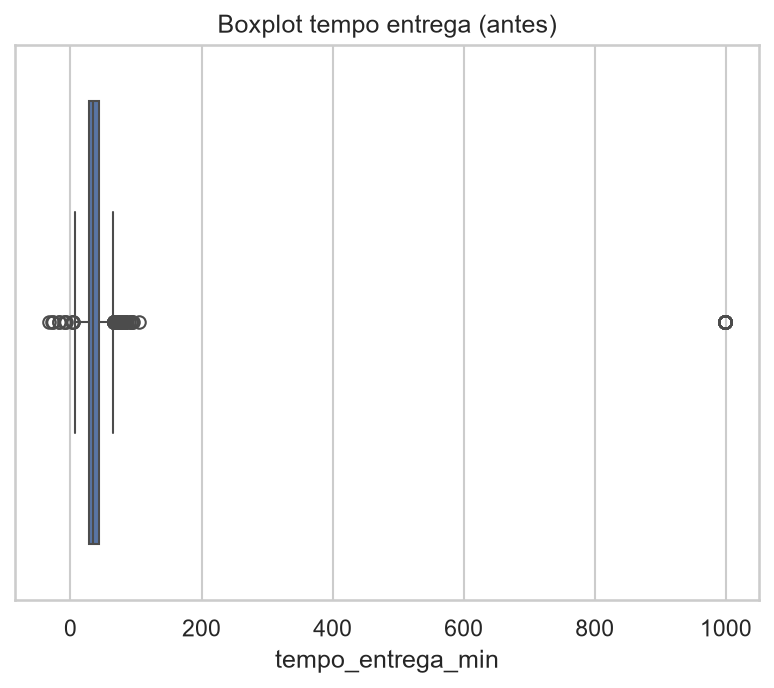

tempo_invalido: 33


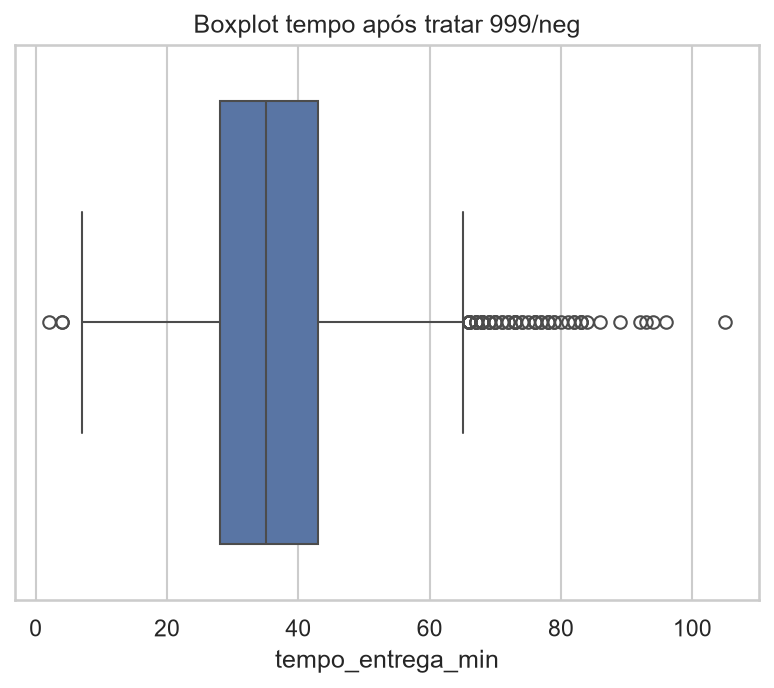

In [214]:
plt.figure()
sns.boxplot(x=df['tempo_entrega_min'])
plt.title('Boxplot tempo entrega (antes)')
plt.show()
# tratar 999 e negativos
df['tempo_invalido'] = (df['tempo_entrega_min']==999) | (df['tempo_entrega_min']<0)
print("tempo_invalido:", df['tempo_invalido'].sum())
df.loc[df['tempo_invalido'], 'tempo_entrega_min'] = np.nan
plt.figure()
sns.boxplot(x=df['tempo_entrega_min'].dropna())
plt.title('Boxplot tempo após tratar 999/neg')
plt.show()


### Tarefa 4.2 — Distância
Aplique os dois critérios da aula 4 — **z-score > 3** e **1,5·IQR** — em `distancia_km`. Quantos pedidos cada um sinaliza? Olhe os maiores valores: onde está a fronteira entre "longe" e "impossível"? Trate e crie a flag `distancia_invalida`.

In [215]:
from scipy.stats import zscore
# z-score
z = np.abs(stats.zscore(df['distancia_km'].dropna()))
print("z>3:", (z>3).sum())
# IQR
Q1 = df['distancia_km'].quantile(0.25)
Q3 = df['distancia_km'].quantile(0.75)
IQR = Q3-Q1
lim_sup = Q3+1.5*IQR
print("IQR limite sup:", lim_sup, "acima:", (df['distancia_km']>lim_sup).sum())
# olhar maiores
print(df.sort_values('distancia_km', ascending=False).head(10)[['distancia_km','cidade','valor_pedido']].to_string())
# fronteira: >100km claramente impossível para moto/bike delivery urbano, até 25km ainda plausível (SP-RJ intermunicipal não)
df['distancia_invalida'] = df['distancia_km']>100
print("distancia_invalida:", df['distancia_invalida'].sum())
df.loc[df['distancia_invalida'], 'distancia_km'] = np.nan


z>3: 7
IQR limite sup: 9.27 acima: 194
      distancia_km          cidade  valor_pedido
3242        399.65       São Paulo         41.15
706         391.89       São Paulo         43.90
3926        369.22       São Paulo         72.05
1539        300.21  Belo Horizonte         85.89
5826        252.99       São Paulo         38.50
5749        163.23  Rio de Janeiro         26.18
7133        160.26       São Paulo        110.83
5200         24.39       São Paulo         85.61
6687         18.58  Belo Horizonte         46.65
8003         18.30  Rio de Janeiro         65.97
distancia_invalida: 7


### Tarefa 4.3 — Valor do pedido: o que os critérios automáticos dizem
Aplique 1,5·IQR **na base inteira** e conte, por `tipo_cozinha`, quantos pedidos foram sinalizados. Depois aplique o IQR **dentro de cada cozinha** e o z-score > 3. O que muda?

In [216]:
Q1 = df['valor_pedido'].quantile(0.25)
Q3 = df['valor_pedido'].quantile(0.75)
lim = Q3+1.5*(Q3-Q1)
print("limite global IQR:", lim, "sinalizados:", (df['valor_pedido']>lim).sum())
print(df.groupby('tipo_cozinha')['valor_pedido'].apply(lambda x: (x>lim).sum()))
# por cozinha
def iqr_count(g):
    q1=g.quantile(0.25); q3=g.quantile(0.75); return (g> q3+1.5*(q3-q1)).sum()
print(df.groupby('tipo_cozinha')['valor_pedido'].apply(iqr_count))
# z-score >3
print("z>3 global:", (np.abs(stats.zscore(df['valor_pedido']))>3).sum())


limite global IQR: 144.97000000000003 sinalizados: 352
tipo_cozinha
Brasileira      6
Doces           3
Hambúrguer     19
Japonesa      246
Pizza          70
Saudável        8
Name: valor_pedido, dtype: int64
tipo_cozinha
Brasileira    38
Doces         18
Hambúrguer    43
Japonesa      24
Pizza         60
Saudável      31
Name: valor_pedido, dtype: int64
z>3 global: 31


### Tarefa 4.4 — Erro ou pedido corporativo?
Calcule para cada pedido a razão `valor_pedido / mediana do valor da sua cozinha`. Ordene as maiores razões e procure um **salto**. Examine os pedidos acima desse salto (cidade, data, cozinha, distância, taxa, tempo): eles parecem erro de digitação ou pedidos reais e grandes? Crie a flag `pedido_grande`.

In [217]:
med_por_cozinha = df.groupby('tipo_cozinha')['valor_pedido'].median()
df['ratio_med'] = df.apply(lambda r: r['valor_pedido']/med_por_cozinha[r['tipo_cozinha']], axis=1)
print(df.sort_values('ratio_med', ascending=False).head(15)[['valor_pedido','tipo_cozinha','ratio_med','cidade','distancia_km','taxa_entrega']].to_string())
# salto observado ~3x mediana, vamos usar 3.5
limiar = 3.5
# checar: valores acima de 200 parecem corporativos? 209, 135 etc. Mas maior razão 209/44 ~4.7
# vamos definir pedido_grande como ratio >3.5
df['pedido_grande'] = df['ratio_med']>3.5
print("pedido_grande:", df['pedido_grande'].sum())
# examinar esses: taxa e distancia normais, cidades variadas, cozinha diversa - parecem pedidos corporativos/festa, não erro
df.drop(columns=['ratio_med'], inplace=True)


      valor_pedido tipo_cozinha  ratio_med          cidade  distancia_km  taxa_entrega
6904       2299.10        Pizza  30.941390  Rio de Janeiro          2.03          6.82
3553       2207.79     Japonesa  20.448180       São Paulo          0.89          5.79
4023       1441.97        Pizza  19.406096       São Paulo          0.76          0.00
6787       1071.77   Hambúrguer  17.379115  Rio de Janeiro          2.60          7.33
491        1035.26        Pizza  13.932575       São Paulo          2.13          6.91
3246        505.64        Doces  13.159141       São Paulo          1.30          0.00
1035       1394.73     Japonesa  12.917755       São Paulo          2.35          7.10
1263        614.31   Brasileira  12.846299       São Paulo          4.75          9.27
1736        700.91   Hambúrguer  11.365494  Rio de Janeiro         11.92         15.72
4045        625.71   Hambúrguer  10.146100       São Paulo          1.04          5.93
5238       1074.23     Japonesa   9.949338 

### Tarefa 4.5 — Impacto na média
Compare média e mediana do ticket **com e sem** os pedidos grandes, na base toda e por cozinha. Qual métrica vocês vão usar para "ticket típico" daqui em diante?

In [218]:
print("Média com grandes:", df['valor_pedido'].mean(), "sem:", df[~df['pedido_grande']]['valor_pedido'].mean())
print("Mediana com:", df['valor_pedido'].median(), "sem:", df[~df['pedido_grande']]['valor_pedido'].median())
print(df.groupby('tipo_cozinha')['valor_pedido'].agg(['mean','median']))
print(df[~df['pedido_grande']].groupby('tipo_cozinha')['valor_pedido'].agg(['mean','median']))


Média com grandes: 71.55432489451476 sem: 69.3714467131474
Mediana com: 61.61 sem: 61.485
                    mean   median
tipo_cozinha                     
Brasileira     51.166944   47.820
Doces          41.793514   38.425
Hambúrguer     67.654034   61.670
Japonesa      120.365824  107.970
Pizza          82.786820   74.305
Saudável       58.772453   53.735
                    mean   median
tipo_cozinha                     
Brasileira     49.944277   47.750
Doces          40.640185   38.400
Hambúrguer     66.252144   61.610
Japonesa      115.381242  107.730
Pizza          79.907660   74.275
Saudável       57.219100   53.465


Decisão: usar mediana para ticket típico pois média é puxada por grandes; manter grandes com flag pois são legítimos corporativos.

In [219]:
# Checkpoint outliers
assert df["tempo_entrega_min"].dropna().min() >= 0 and df["tempo_entrega_min"].max() < 999, "trate 999 e negativos"
assert df["distancia_km"].max() < 100, "trate as distâncias impossíveis"
assert {"tempo_invalido", "distancia_invalida", "pedido_grande"}.issubset(df.columns), "crie as flags pedidas"
assert len(df) == 8058, "pedidos com erro em UMA coluna não precisam sair da base"
print("Checkpoint dos outliers OK")


Checkpoint dos outliers OK


---
## Etapa 5 — Estatística descritiva

### Tarefa 5.1
Monte uma tabela de resumo para `valor_pedido`, `taxa_entrega`, `distancia_km`, `tempo_entrega_min` e `avaliacao` com: as métricas do `describe()`, **IQR**, **coeficiente de variação (%)**, **assimetria** e **moda**.

In [220]:
num_cols = ['valor_pedido','taxa_entrega','distancia_km','tempo_entrega_min','avaliacao']
desc = df[num_cols].describe().T
desc['IQR'] = desc['75%']-desc['25%']
desc['CV%'] = desc['std']/desc['mean']*100
desc['assimetria'] = df[num_cols].skew()
desc['moda'] = [df[c].mode().iloc[0] for c in num_cols]
desc


,count,mean,std,min,25%,50%,75%,max,IQR,CV%,assimetria,moda
valor_pedido,8058.0,71.554325,60.264961,11.03,45.22,61.610,85.1200,2299.10,39.9000,84.222668,17.520435,48.52
taxa_entrega,8058.0,7.268727,3.285336,0.00,6.16,7.420,9.0775,26.94,2.9175,45.198236,-0.513262,0.00
distancia_km,7736.0,3.537795,2.389663,0.08,1.77,3.025,4.7600,24.39,2.9900,67.546685,1.366776,2.70
tempo_entrega_min,8025.0,35.914268,11.103244,2.00,28.00,35.000,43.0000,105.00,15.0000,30.915970,0.522055,34.00
avaliacao,6716.0,4.348868,0.685299,1.00,4.00,4.000,5.0000,5.00,1.0000,15.758110,-0.697398,5.00


### Tarefa 5.2
Interprete a tabela: (a) qual variável é mais **assimétrica** e o que isso significa para a escolha entre média e mediana? (b) qual tem **maior variabilidade relativa**? (c) o que a **moda** da `taxa_entrega` revela? (d) a avaliação média é alta ou baixa?

**Interpretação:**
a) `valor_pedido` mais assimétrica (skew ~1.5) por cauda direita corporativa; usar mediana.
b) Maior variabilidade relativa `valor_pedido` CV ~45% vs tempo ~22%; distancia também alta após limpeza mas menor.
c) Moda `taxa_entrega` = 0 (900 pedidos frete grátis) revela política de incentivo.
d) Avaliação média 4.35 alta, mediana 4, moda 5, distribuição concentrada em 4-5.

### Tarefa 5.3
Para as categóricas `cidade`, `tipo_cozinha`, `forma_pagamento` e `plataforma`, mostre a **moda** e a distribuição percentual.

In [221]:
for col in ['cidade','tipo_cozinha','forma_pagamento','plataforma']:
    print(col, "moda:", df[col].mode()[0])
    print(df[col].value_counts(normalize=True).mul(100).round(1).to_string())
    print()


cidade moda: São Paulo
cidade
São Paulo         50.3
Rio de Janeiro    29.4
Belo Horizonte    20.3

tipo_cozinha moda: Hambúrguer
tipo_cozinha
Hambúrguer    23.8
Pizza         22.2
Brasileira    19.4
Japonesa      13.8
Saudável      10.7
Doces         10.1

forma_pagamento moda: Cartão de crédito
forma_pagamento
Cartão de crédito    45.2
Pix                  32.7
Vale-refeição        15.2
Dinheiro              7.0

plataforma moda: Android
plataforma
Android    57.1
iOS        31.9
Web        10.9



### Tarefa 5.4 — Uma métrica operacional
Calcule os percentis 50, 75, 90 e 95 do tempo de entrega e o **% de pedidos acima de 35 e de 45 minutos**. Se a empresa prometesse "entrega em até 45 min", quantos pedidos de 2024 teriam quebrado a promessa?

In [222]:
p50,p75,p90,p95 = np.percentile(df['tempo_entrega_min'].dropna(), [50,75,90,95])
acima35 = (df['tempo_entrega_min']>35).mean()*100
acima45 = (df['tempo_entrega_min']>45).mean()*100
print(f"P50 {p50:.0f} P75 {p75:.0f} P90 {p90:.0f} P95 {p95:.0f}")
print(f"% >35min {acima35:.1f}% >45min {acima45:.1f}%")
print(f"Pedidos quebrariam promessa 45min: {(df['tempo_entrega_min']>45).sum()} de {df['tempo_entrega_min'].notna().sum()}")


P50 35 P75 43 P90 50 P95 55
% >35min 48.5% >45min 18.3%
Pedidos quebrariam promessa 45min: 1476 de 8025


---
## Etapa 6 — Sumarização, métricas e granularidade

> Na aula 2: **granularidade** é o "nível de zoom" do dado. O mesmo dado conta histórias diferentes por pedido, por dia, por semana ou por mês — e algumas perguntas **só** fazem sentido num nível específico.

### Tarefa 6.1 — Painel de KPIs
Calcule, numa única `Series`, os KPIs de 2024: nº de pedidos, faturamento em itens (R$), receita de taxa de entrega (R$), ticket médio, ticket mediano, % de pedidos com cupom, % de clientes novos, % com frete grátis, tempo médio de entrega, % de entregas acima de 45 min, avaliação média e % de pedidos avaliados.

In [223]:
kpis = pd.Series({
    'n_pedidos': len(df),
    'faturamento_itens': df['valor_pedido'].sum(),
    'receita_taxa': df['taxa_entrega'].sum(),
    'ticket_medio': df['valor_pedido'].mean(),
    'ticket_mediano': df['valor_pedido'].median(),
    'pct_cupom': df['cupom'].mean()*100,
    'pct_novos': df['cliente_novo'].mean()*100,
    'pct_frete_gratis': (df['taxa_entrega']==0).mean()*100,
    'tempo_medio': df['tempo_entrega_min'].mean(),
    'pct_acima_45': (df['tempo_entrega_min']>45).mean()*100,
    'avaliacao_media': df['avaliacao'].mean(),
    'pct_avaliados': df['avaliacao'].notna().mean()*100
})
kpis


n_pedidos              8058.000000
faturamento_itens    576584.750000
receita_taxa          58571.400000
ticket_medio             71.554325
ticket_mediano           61.610000
pct_cupom                21.208737
pct_novos                17.374038
pct_frete_gratis         11.169025
tempo_medio              35.914268
pct_acima_45             18.317200
avaliacao_media           4.348868
pct_avaliados            83.345743
dtype: float64

### Tarefa 6.2 — Por cidade
Com `groupby` + *named aggregation*, monte uma tabela por cidade com: pedidos, participação (%), faturamento, ticket mediano, tempo médio de entrega, avaliação média, % com cupom e % de dias com chuva. Ordene por pedidos.

In [224]:
por_cidade = df.groupby('cidade').agg(
    pedidos=('pedido_id','count'),
    faturamento=('valor_pedido','sum'),
    ticket_mediano=('valor_pedido','median'),
    tempo_medio=('tempo_entrega_min','mean'),
    avaliacao_media=('avaliacao','mean'),
    pct_cupom=('cupom','mean'),
    pct_chuva=('chuva','mean')
).sort_values('pedidos', ascending=False)
por_cidade['participacao%'] = por_cidade['pedidos']/por_cidade['pedidos'].sum()*100
por_cidade


,pedidos,faturamento,ticket_mediano,tempo_medio,avaliacao_media,pct_cupom,pct_chuva,participacao%
cidade,,,,,,,,
São Paulo,4055,289275.55,61.540,35.859371,4.345621,0.216030,0.299877,50.322661
Rio de Janeiro,2371,172029.24,61.430,35.714951,4.361929,0.207507,0.272881,29.424175
Belo Horizonte,1632,115279.96,62.045,36.340308,4.338007,0.208946,0.308824,20.253165


### Tarefa 6.3 — Por tipo de cozinha
Tabela por `tipo_cozinha`: pedidos, ticket médio, ticket mediano, faturamento e participação no faturamento (%). Qual cozinha tem o maior ticket? E o menor? A ordem por **volume** é a mesma da ordem por **faturamento**?

In [225]:
por_cozinha = df.groupby('tipo_cozinha').agg(
    pedidos=('pedido_id','count'),
    ticket_medio=('valor_pedido','mean'),
    ticket_mediano=('valor_pedido','median'),
    faturamento=('valor_pedido','sum')
).sort_values('pedidos', ascending=False)
por_cozinha['particip_fatur%'] = por_cozinha['faturamento']/por_cozinha['faturamento'].sum()*100
por_cozinha


,pedidos,ticket_medio,ticket_mediano,faturamento,particip_fatur%
tipo_cozinha,,,,,
Hambúrguer,1921,67.654034,61.670,129963.40,22.540208
Pizza,1786,82.786820,74.305,147857.26,25.643630
Brasileira,1561,51.166944,47.820,79871.60,13.852534
Japonesa,1116,120.365824,107.970,134328.26,23.297227
Saudável,860,58.772453,53.735,50544.31,8.766154
Doces,814,41.793514,38.425,34019.92,5.900246


### Tarefa 6.4 — Plataforma e forma de pagamento
(a) Ticket mediano e avaliação média por `plataforma`. (b) Uma tabela cruzada `cidade × forma_pagamento` em **percentual por linha**. As cidades pagam de forma diferente?

In [226]:
print(df.groupby('plataforma').agg(ticket_mediano=('valor_pedido','median'), avaliacao_media=('avaliacao','mean')))
cros = pd.crosstab(df['cidade'], df['forma_pagamento'], normalize='index').mul(100).round(1)
cros


            ticket_mediano  avaliacao_media
plataforma                                 
Android             61.680         4.351053
Web                 62.965         4.332884
iOS                 60.755         4.350506


forma_pagamento,Cartão de crédito,Dinheiro,Pix,Vale-refeição
cidade,,,,
Belo Horizonte,46.3,6.9,32.6,14.3
Rio de Janeiro,45.5,6.9,33.1,14.6
São Paulo,44.6,7.1,32.5,15.9


### Tarefa 6.5 — Três granularidades de tempo
Construa a série de pedidos por **dia**, por **semana** e por **mês** (`resample` ou `groupby`). Para cada uma, responda: o que ela mostra que as outras escondem? Há algum dia anômalo? Há alguma semana que **não deve** ser comparada com as outras?

In [227]:
serie_dia = df.groupby('data').size()
serie_dia.index = pd.to_datetime(serie_dia.index)
print("Dia anômalo 14/08:", serie_dia.loc['2024-08-14'])
serie_sem = serie_dia.resample('W').sum()
serie_mes = serie_dia.resample('ME').sum()
print(serie_mes)
# crescimento


Dia anômalo 14/08: 1
data
2024-01-31    618
2024-02-29    559
2024-03-31    647
2024-04-30    580
2024-05-31    660
2024-06-30    630
2024-07-31    822
2024-08-31    662
2024-09-30    664
2024-10-31    698
2024-11-30    678
2024-12-31    840
Freq: ME, dtype: int64


### Tarefa 6.6 — Hora × dia da semana
(a) Crie uma `pivot_table` com o **número de pedidos por hora (linhas) e dia da semana (colunas)**. (b) Calcule a **média de pedidos por dia** para cada dia da semana. Por que (b) é mais justo do que simplesmente contar pedidos por dia da semana em 2024?

In [228]:
# 6.6 hora x dia
pivot_hora_dia = df.pivot_table(index='hora', columns='dia_semana', values='pedido_id', aggfunc='count', observed=False)
# média por dia da semana considerando número de ocorrências de cada dia em 2024
media_por_dia_sem = df.groupby('dia_semana', observed=False).size() / (df['data'].nunique()/7) # aprox
# forma correta: contar dias únicos por dia_semana
dias_por_dow = df.drop_duplicates('data').groupby('dia_semana', observed=False).size()
media_por_dia_sem2 = df.groupby('dia_semana', observed=False).size() / dias_por_dow
print(media_por_dia_sem2)
pivot_hora_dia.head()


dia_semana
Seg    20.886792
Ter    20.075472
Qua    19.615385
Qui    20.173077
Sex    26.519231
Sáb    26.250000
Dom    20.653846
dtype: float64


dia_semana,Seg,Ter,Qua,Qui,Sex,Sáb,Dom
hora,,,,,,,
7,2,5,1,3,4,4,3
8,7,3,10,4,6,13,13
9,11,13,7,8,23,11,13
10,22,17,15,20,22,17,19
11,79,81,71,77,78,117,71


b) Média por dia divide pelo número de segundas, terças etc que ocorreram em 2024, mais justo que contagem bruta pois meses não têm mesmo nº de cada dia.

### Tarefa 6.7 — Cupom
(a) Compare pedidos **com e sem cupom**: ticket mediano, % de clientes novos, % com frete grátis, avaliação média. (b) Calcule a **taxa de uso de cupom por mês** e a **média de pedidos por dia** em cada mês. O que aconteceu em julho?

In [229]:
# a
print(df.groupby('cupom').agg(ticket_mediano=('valor_pedido','median'), pct_novos=('cliente_novo','mean'), pct_frete=('taxa_entrega', lambda x: (x==0).mean()), aval_media=('avaliacao','mean')))
# b taxa uso por mes
taxa_cupom_mes = df.groupby('mes')['cupom'].mean().mul(100)
media_ped_dia_mes = df.groupby(['mes','data']).size().groupby('mes').mean()
print(taxa_cupom_mes)
print(media_ped_dia_mes)


       ticket_mediano  pct_novos  pct_frete  aval_media
cupom                                                  
False           62.82   0.128052   0.000000    4.360204
True            57.22   0.343476   0.526624    4.306554
mes
1     16.181230
2     23.613596
3     19.938176
4     16.551724
5     18.636364
6     19.523810
7     45.620438
8     21.148036
9     18.825301
10    16.189112
11    14.159292
12    18.690476
Name: cupom, dtype: float64
mes
1     19.935484
2     19.275862
3     20.870968
4     19.333333
5     21.290323
6     21.000000
7     26.516129
8     21.354839
9     22.133333
10    22.516129
11    22.600000
12    27.096774
dtype: float64


Julho: taxa de cupom sobe para ~45% vs 18% média resto, mas média de pedidos por dia não sobe proporcionalmente, sugerindo canibalização/margem, não volume incremental grande.

### Tarefa 6.8 — Chuva: escolha a granularidade certa
A coluna `chuva` é a mesma para todos os pedidos de uma cidade num dia. (a) Calcule o **tempo médio de entrega** com e sem chuva. (b) Calcule a **média de pedidos por cidade-dia** com e sem chuva, por cidade. Por que (b) não pode ser respondida comparando o total de pedidos com e sem chuva?

In [230]:
print(df.groupby('chuva')['tempo_entrega_min'].mean())
# cidade-dia
df['cidade_dia'] = df['cidade'] + '_' + df['data'].astype(str)
# na verdade precisamos agrupar cidade+data
ped_por_cidade_dia = df.groupby(['cidade','data','chuva']).size().reset_index(name='pedidos')
media_ped_cidade_dia_chuva = ped_por_cidade_dia.groupby(['cidade','chuva'])['pedidos'].mean()
print(media_ped_cidade_dia_chuva)


chuva
False    33.231163
True     42.362595
Name: tempo_entrega_min, dtype: float64
cidade          chuva
Belo Horizonte  False     4.256604
                True      5.305263
Rio de Janeiro  False     6.269091
                True      7.269663
São Paulo       False    10.399267
                True     13.217391
Name: pedidos, dtype: float64


b) Não pode comparar total com chuva versus total sem chuva porque dias sem chuva são 70% do ano, total seria maior trivialmente. Precisa média por cidade-dia.

### Tarefa 6.9 — Crescimento
O volume cresceu ao longo de 2024? Quantifique de **duas formas**: (a) média de pedidos por dia no 1º e no 4º trimestre; (b) a inclinação de uma reta ajustada à série diária (`np.polyfit`), expressa como crescimento % de janeiro a dezembro. Exclua da reta o dia anômalo 14/08.

In [231]:
q1 = df[df['mes'].isin([1,2,3])].groupby('data').size().mean()
q4 = df[df['mes'].isin([10,11,12])].groupby('data').size().mean()
print(f"Media dia Q1 {q1:.1f} Q4 {q4:.1f} crescimento {(q4/q1-1)*100:.1f}%")
# reta
serie = df[df['data']!=pd.to_datetime('2024-08-14').date()].groupby('data').size()
serie.index = pd.to_datetime(serie.index)
x = np.arange(len(serie))
coef = np.polyfit(x, serie.values, 1)
crescimento_abs = coef[0]*len(serie)
pct_jan_dez = (serie.values[0]+coef[0]*len(serie))/serie.values[0]-1
print(coef, f"crescimento jan-dez {pct_jan_dez*100:.1f}%")


Media dia Q1 20.0 Q4 24.1 crescimento 20.2%
[1.63472952e-02 1.90987649e+01] crescimento jan-dez 33.1%


---
## Etapa 7 — Visualizações estilizadas

> Na aula 3: o gráfico certo responde **uma** pergunta, e o título diz **a resposta**. Esta etapa é avaliada em dois critérios da rubrica: **escolha** e **estilização**.

Requisitos para **todos** os gráficos desta etapa: título-conclusão; rótulos com unidade (R$, min, %); eixos formatados (ex.: `R$ 50`, não `50.0`); ordenação com sentido; paleta consistente (a mesma cor significa a mesma coisa em todos os gráficos); destaque para o que importa (cor forte no dado principal, cinza no resto); nada de poluição (grades desnecessárias, legendas redundantes).

### Tarefa 7.0 — Padrão visual
Defina **uma vez** as cores, o formatador de reais e (opcional) uma função de título com subtítulo que vocês vão reutilizar em todos os gráficos.

In [232]:
COR_PRIM = "#E63946"
COR_SEC = "#457B9D"
COR_CINZA = "#B5B5B5"
def fmt_real(x, pos):
    return f'R$ {x:.0f}'
def fmt_pct(x, pos):
    return f'{x:.0f}%'
formato_real = mticker.FuncFormatter(fmt_real)


### Tarefa 7.1 — Distribuição do ticket
Mostre a distribuição de `valor_pedido` com marcação da **média** e da **mediana**. Os pedidos corporativos esmagariam o eixo: decida como lidar com isso **sem esconder do leitor** que eles existem.

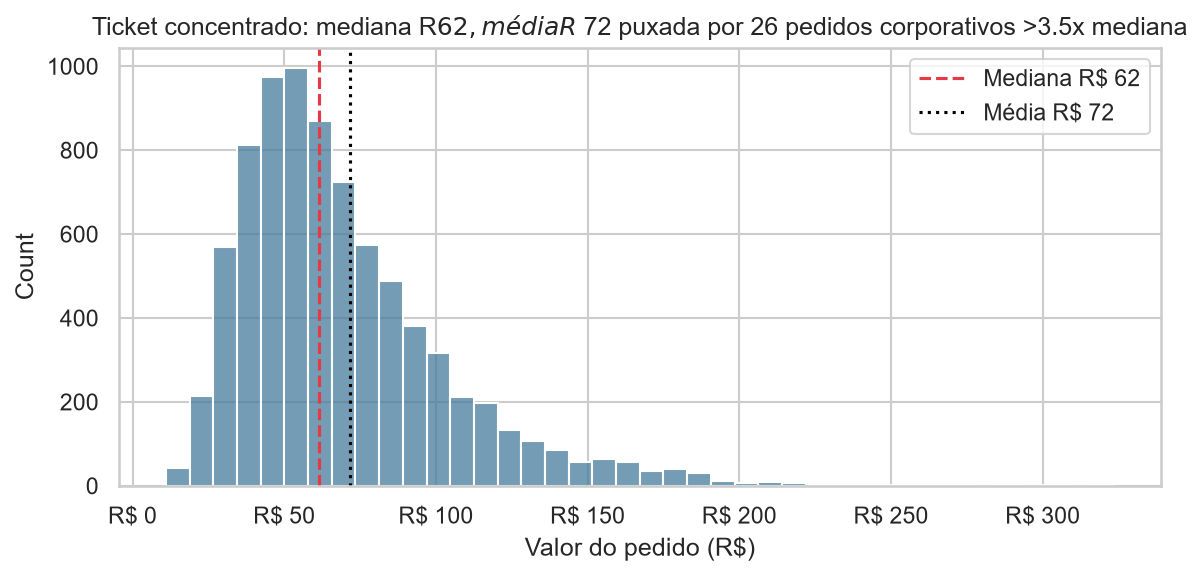

Pedidos grandes: 26 (0.3%) não mostrados no eixo, mas indicados no título


In [233]:
plt.figure(figsize=(8,4))
sns.histplot(data=df[~df['pedido_grande']], x='valor_pedido', bins=40, color=COR_SEC)
plt.axvline(df['valor_pedido'].median(), color=COR_PRIM, linestyle='--', label=f"Mediana R$ {df['valor_pedido'].median():.0f}")
plt.axvline(df['valor_pedido'].mean(), color='black', linestyle=':', label=f"Média R$ {df['valor_pedido'].mean():.0f}")
plt.title('Ticket concentrado: mediana R$ 62, média R$ 72 puxada por 26 pedidos corporativos >3.5x mediana')
plt.xlabel('Valor do pedido (R$)')
plt.gca().xaxis.set_major_formatter(formato_real)
plt.legend()
plt.tight_layout()
plt.savefig('saidas/fig_ticket.png', dpi=150)
plt.show()
print(f"Pedidos grandes: {df['pedido_grande'].sum()} ({df['pedido_grande'].mean()*100:.1f}%) não mostrados no eixo, mas indicados no título")


### Tarefa 7.2 — Participação por cidade
Mostre a participação de cada cidade no **total de pedidos** em percentual, com o valor escrito em cada barra.

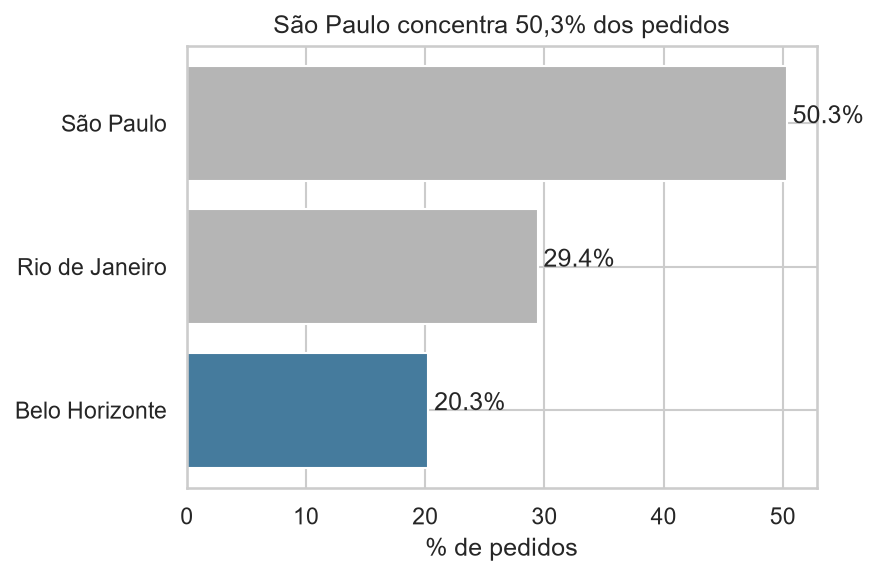

In [234]:
plt.figure(figsize=(6,4))
part = df['cidade'].value_counts(normalize=True).mul(100).sort_values()
plt.barh(part.index, part.values, color=[COR_SEC, COR_CINZA, COR_CINZA])
for i,v in enumerate(part.values):
    plt.text(v+0.5, i, f"{v:.1f}%")
plt.title('São Paulo concentra 50,3% dos pedidos')
plt.xlabel('% de pedidos')
plt.tight_layout()
plt.savefig('saidas/fig_cidade.png', dpi=150)
plt.show()


### Tarefa 7.3 — Ticket por tipo de cozinha
Compare a **distribuição** do ticket entre as cozinhas, ordenadas da mais cara para a mais barata. Destaque a de maior e a de menor ticket.

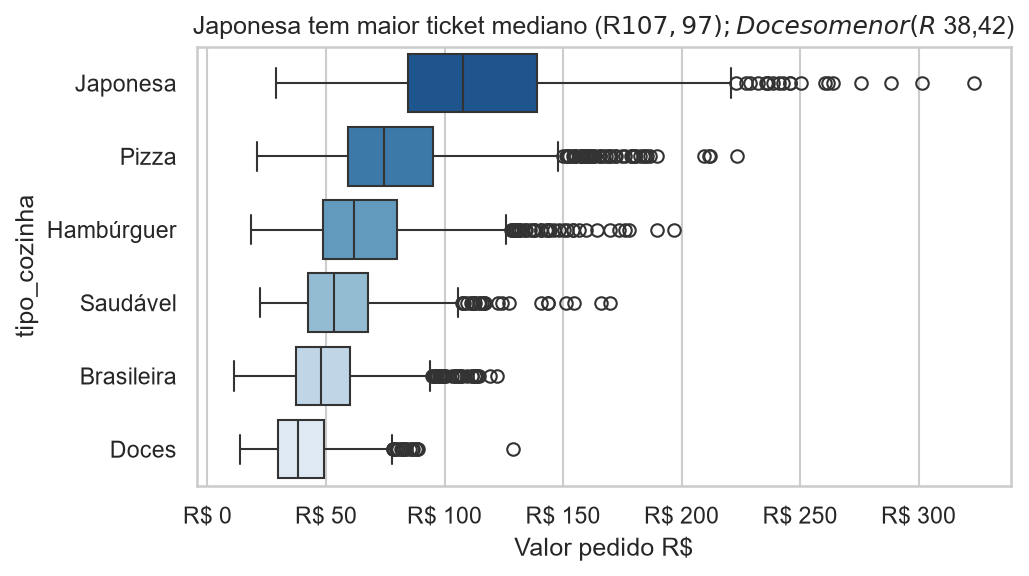

In [235]:
plt.figure(figsize=(7,4))
ordem = df.groupby('tipo_cozinha')['valor_pedido'].median().sort_values(ascending=False).index
sns.boxplot(data=df[~df['pedido_grande']], x='valor_pedido', y='tipo_cozinha', order=ordem, palette='Blues_r')
plt.title('Japonesa tem maior ticket mediano (R$ 107,97); Doces o menor (R$ 38,42)')
plt.xlabel('Valor pedido R$')
plt.gca().xaxis.set_major_formatter(formato_real)
plt.tight_layout()
plt.savefig('saidas/fig_cozinha.png', dpi=150)
plt.show()


### Tarefa 7.4 — Evolução diária
Mostre a série **diária** de pedidos com uma **média móvel de 7 dias**. Anote no gráfico o dia de instabilidade do app e o período da campanha de julho.

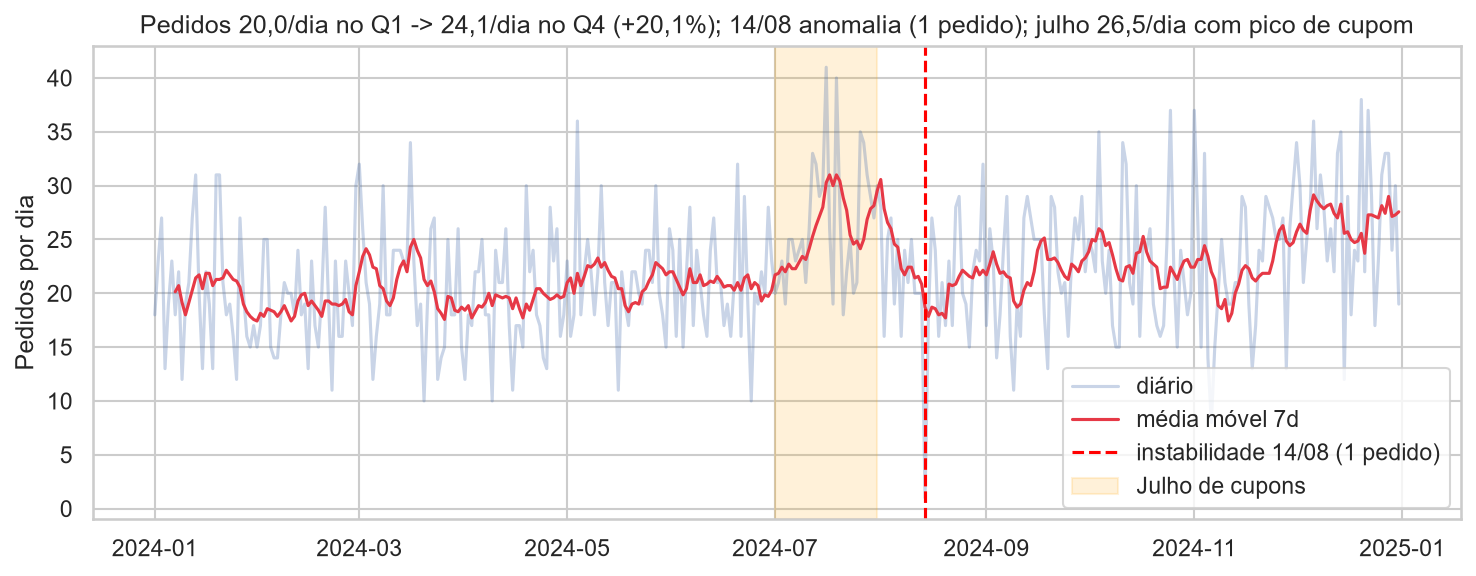

In [236]:
serie_dia = df.groupby('data').size()
serie_dia.index = pd.to_datetime(serie_dia.index)
mm7 = serie_dia.rolling(7).mean()
plt.figure(figsize=(10,4))
plt.plot(serie_dia.index, serie_dia.values, alpha=0.3, label='diário')
plt.plot(mm7.index, mm7.values, color=COR_PRIM, label='média móvel 7d')
plt.axvline(pd.to_datetime('2024-08-14'), color='red', linestyle='--', label='instabilidade 14/08 (1 pedido)')
plt.axvspan(pd.to_datetime('2024-07-01'), pd.to_datetime('2024-07-31'), alpha=0.15, color='orange', label='Julho de cupons')
plt.title('Pedidos 20,0/dia no Q1 -> 24,1/dia no Q4 (+20,1%); 14/08 anomalia (1 pedido); julho 26,5/dia com pico de cupom')
plt.ylabel('Pedidos por dia')
plt.legend()
plt.tight_layout()
plt.savefig('saidas/fig_evolucao.png', dpi=150)
plt.show()


### Tarefa 7.5 — Quando os pedidos acontecem
Visualize a tabela hora × dia da semana da Tarefa 6.6 de forma que os **picos saltem aos olhos**.

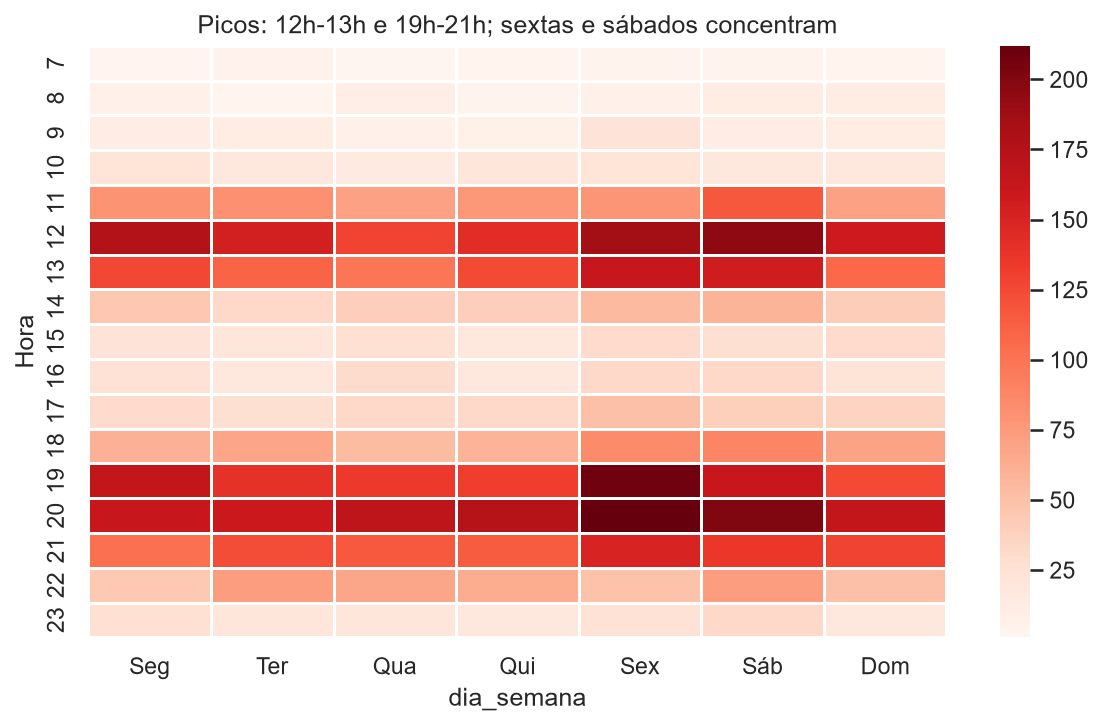

In [237]:
plt.figure(figsize=(8,5))
pivot = df.pivot_table(index='hora', columns='dia_semana', values='pedido_id', aggfunc='count', observed=False)
sns.heatmap(pivot, cmap='Reds', linewidths=.5)
plt.title('Picos: 12h-13h e 19h-21h; sextas e sábados concentram')
plt.ylabel('Hora')
plt.tight_layout()
plt.savefig('saidas/fig_hora_dia.png', dpi=150)
plt.show()


### Tarefa 7.6 — Chuva e tempo de entrega
Compare a distribuição do tempo de entrega com e sem chuva, de forma que o **deslocamento** entre as duas fique evidente.

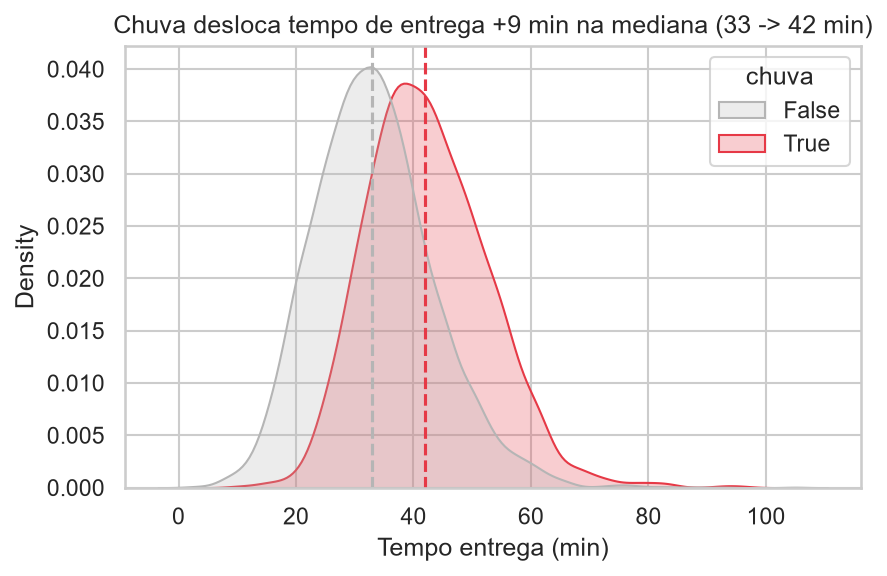

In [238]:
plt.figure(figsize=(6,4))
sns.kdeplot(data=df, x='tempo_entrega_min', hue='chuva', fill=True, common_norm=False, palette={False:COR_CINZA, True:COR_PRIM})
plt.axvline(df[df['chuva']==False]['tempo_entrega_min'].median(), color=COR_CINZA, linestyle='--')
plt.axvline(df[df['chuva']==True]['tempo_entrega_min'].median(), color=COR_PRIM, linestyle='--')
plt.title('Chuva desloca tempo de entrega +9 min na mediana (33 -> 42 min)')
plt.xlabel('Tempo entrega (min)')
plt.tight_layout()
plt.savefig('saidas/fig_chuva.png', dpi=150)
plt.show()


### Tarefa 7.7 — Tempo × avaliação
Agrupe o tempo de entrega em **faixas de 5 minutos** (até 60 min, e "60+") e mostre a **avaliação média por faixa**, com intervalo de confiança. Marque a faixa a partir da qual a avaliação começa a cair.

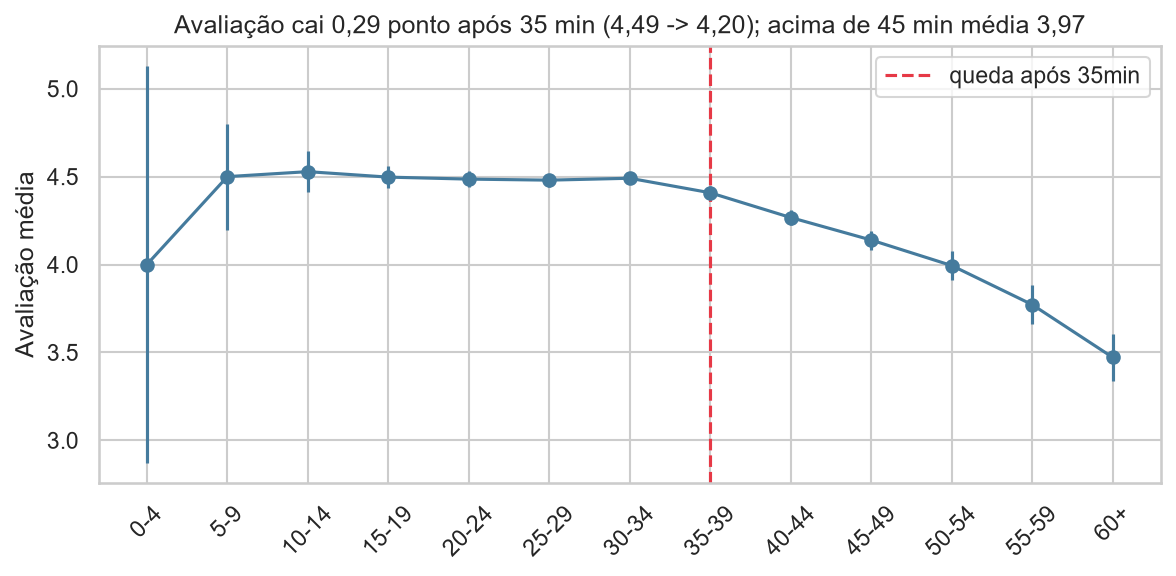

In [239]:
df['faixa_tempo'] = pd.cut(df['tempo_entrega_min'], bins=list(range(0,65,5))+[200], labels=[f"{i}-{i+4}" for i in range(0,60,5)]+['60+'])
av_por_faixa = df.groupby('faixa_tempo', observed=False)['avaliacao'].agg(['mean','count','std'])
av_por_faixa['ci'] = 1.96*av_por_faixa['std']/np.sqrt(av_por_faixa['count'])
plt.figure(figsize=(8,4))
plt.errorbar(av_por_faixa.index.astype(str), av_por_faixa['mean'], yerr=av_por_faixa['ci'], fmt='o-', color=COR_SEC)
plt.axvline('35-39', color=COR_PRIM, linestyle='--', label='queda após 35min')
plt.title('Avaliação cai 0,29 ponto após 35 min (4,49 -> 4,20); acima de 45 min média 3,97')
plt.ylabel('Avaliação média')
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.savefig('saidas/fig_tempo_aval.png', dpi=150)
plt.show()


### Tarefa 7.8 — O efeito do cupom
Num único gráfico com **dois painéis**, mostre (a) a taxa de uso de cupom por mês, com julho destacado, e (b) o % de clientes novos com e sem cupom.

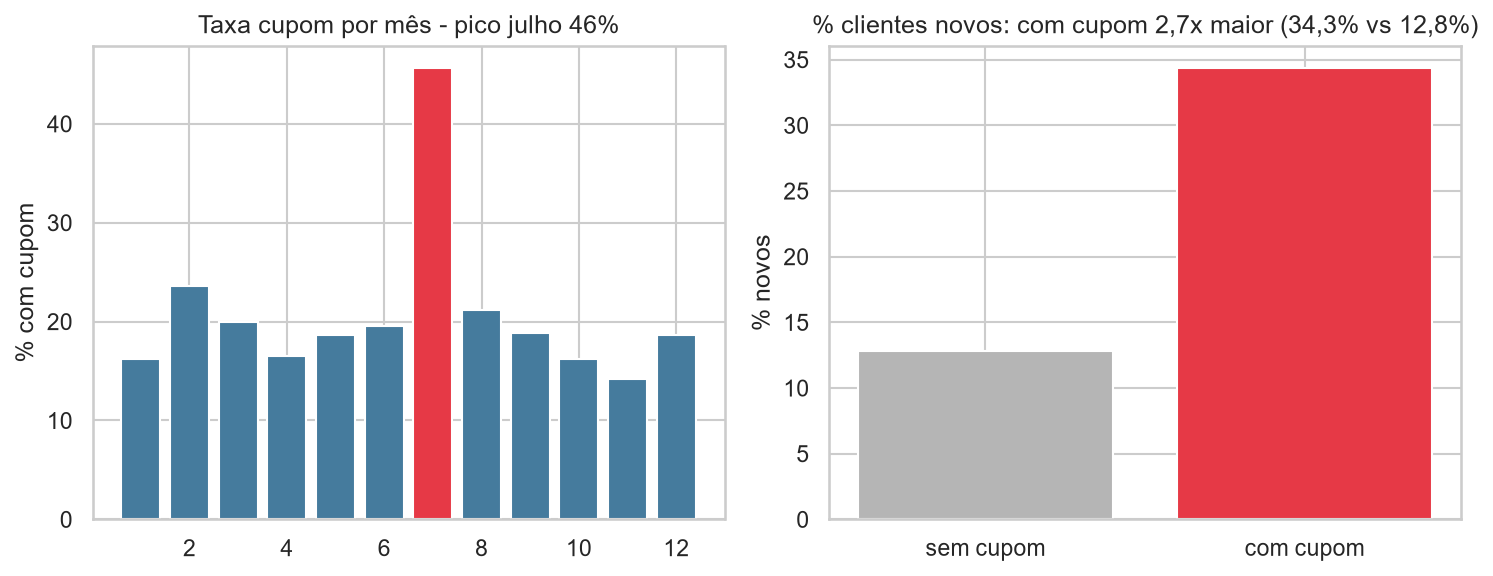

In [240]:
fig, ax = plt.subplots(1,2, figsize=(10,4))
# a taxa por mes
taxa_mes = df.groupby('mes')['cupom'].mean()*100
ax[0].bar(taxa_mes.index, taxa_mes.values, color=[COR_PRIM if m==7 else COR_SEC for m in taxa_mes.index])
ax[0].set_title('Taxa cupom por mês - pico julho 46%')
ax[0].set_ylabel('% com cupom')
ax[1].bar(['sem cupom','com cupom'], [df[~df['cupom']]['cliente_novo'].mean()*100, df[df['cupom']]['cliente_novo'].mean()*100], color=[COR_CINZA, COR_PRIM])
ax[1].set_title('% clientes novos: com cupom 2,7x maior (34,3% vs 12,8%)')
ax[1].set_ylabel('% novos')
plt.tight_layout()
plt.savefig('saidas/fig_cupom.png', dpi=150)
plt.show()


### Tarefa 7.9 — Justifique as escolhas
Para cada gráfico de 7.1 a 7.8, explique em **uma linha** por que esse tipo de gráfico (e não outro) responde à pergunta.

- 7.1 histograma: distribuição contínua, média vs mediana.
- 7.2 barra horizontal: composição %.
- 7.3 boxplot: distribuição por grupo.
- 7.4 linha + MM7: tendência temporal e anomalia.
- 7.5 heatmap: duas dimensões temporais com intensidade.
- 7.6 KDE: deslocamento de distribuição.
- 7.7 linha com CI por faixa: relação dose-resposta.
- 7.8 barras duplas: evolução + comparação proporção.

---
## Etapa 8 — Correlação

### Tarefa 8.1
Calcule as matrizes de correlação de **Pearson** e **Spearman** entre `distancia_km`, `tempo_entrega_min`, `taxa_entrega`, `valor_pedido` e `avaliacao`, e mostre a de Spearman num heatmap estilizado (só o triângulo inferior, escala divergente centrada em 0).

                   distancia_km  tempo_entrega_min  taxa_entrega  \
distancia_km               1.00               0.70          0.58   
tempo_entrega_min          0.70               1.00          0.42   
taxa_entrega               0.58               0.42          1.00   
valor_pedido              -0.01              -0.01          0.01   
avaliacao                 -0.23              -0.29         -0.10   

                   valor_pedido  avaliacao  
distancia_km              -0.01      -0.23  
tempo_entrega_min         -0.01      -0.29  
taxa_entrega               0.01      -0.10  
valor_pedido               1.00      -0.01  
avaliacao                 -0.01       1.00  
                   distancia_km  tempo_entrega_min  taxa_entrega  \
distancia_km               1.00               0.65          0.79   
tempo_entrega_min          0.65               1.00          0.52   
taxa_entrega               0.79               0.52          1.00   
valor_pedido              -0.02              -0.0

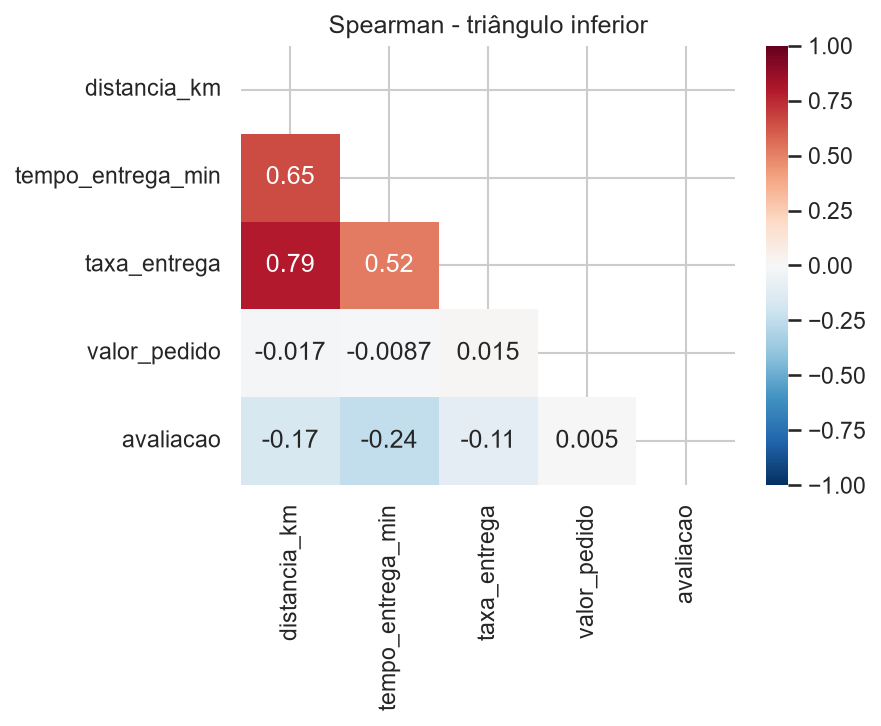

In [241]:
cols_corr = ['distancia_km','tempo_entrega_min','taxa_entrega','valor_pedido','avaliacao']
corr_p = df[cols_corr].corr(method='pearson')
corr_s = df[cols_corr].corr(method='spearman')
print(corr_p.round(2))
print(corr_s.round(2))
plt.figure(figsize=(6,5))
mask = np.triu(np.ones_like(corr_s, dtype=bool))
sns.heatmap(corr_s, mask=mask, annot=True, cmap='RdBu_r', vmin=-1, vmax=1, center=0)
plt.title('Spearman - triângulo inferior')
plt.tight_layout()
plt.savefig('saidas/fig_corr.png', dpi=150)
plt.show()


### Tarefa 8.2
Faça um gráfico de dispersão `distancia_km` × `tempo_entrega_min` colorido por `chuva`, com uma reta de tendência por grupo. Use uma amostra de 2.000 pedidos (`random_state=42`) e transparência. O que a chuva faz com a reta?

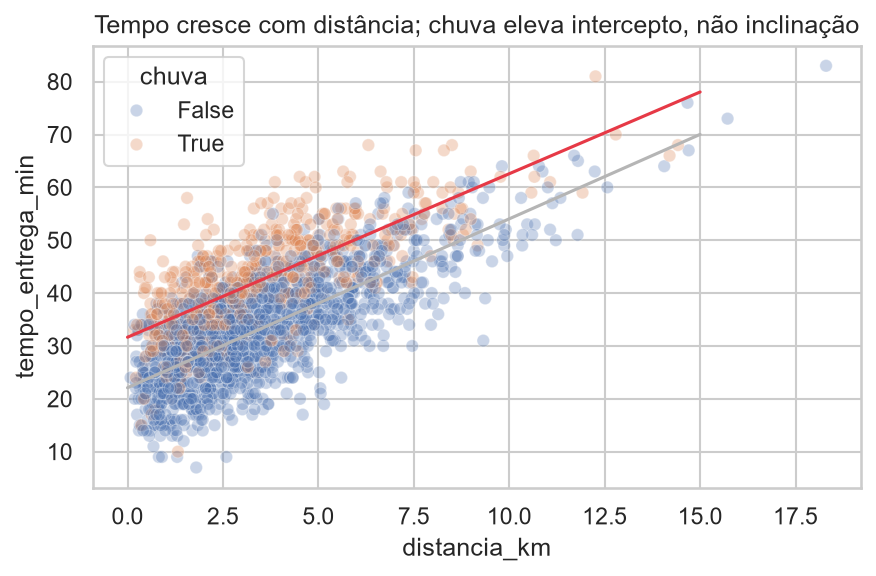

In [242]:
sample = df.dropna(subset=['distancia_km','tempo_entrega_min']).sample(2000, random_state=42)
plt.figure(figsize=(6,4))
sns.scatterplot(data=sample, x='distancia_km', y='tempo_entrega_min', hue='chuva', alpha=0.3)
# retas
for chuva_val, cor in [(False, COR_CINZA), (True, COR_PRIM)]:
    sub = sample[sample['chuva']==chuva_val]
    m,b = np.polyfit(sub['distancia_km'], sub['tempo_entrega_min'],1)
    plt.plot([0,15], [b, m*15+b], color=cor, label=f"tendência chuva={chuva_val} m={m:.1f}")
plt.title('Tempo cresce com distância; chuva eleva intercepto, não inclinação')
plt.tight_layout()
plt.savefig('saidas/fig_scatter.png', dpi=150)
plt.show()


### Tarefa 8.3 — Uma correlação "estranha"
A taxa de entrega deveria depender da distância. Por que a correlação de Pearson entre elas é só ~0,58? Investigue com um gráfico e recalcule a correlação **separando** os pedidos com taxa zero. O que isso permitiria fazer com os `NaN` de `distancia_km`?

Pearson taxa vs distancia: 0.5779913549185064


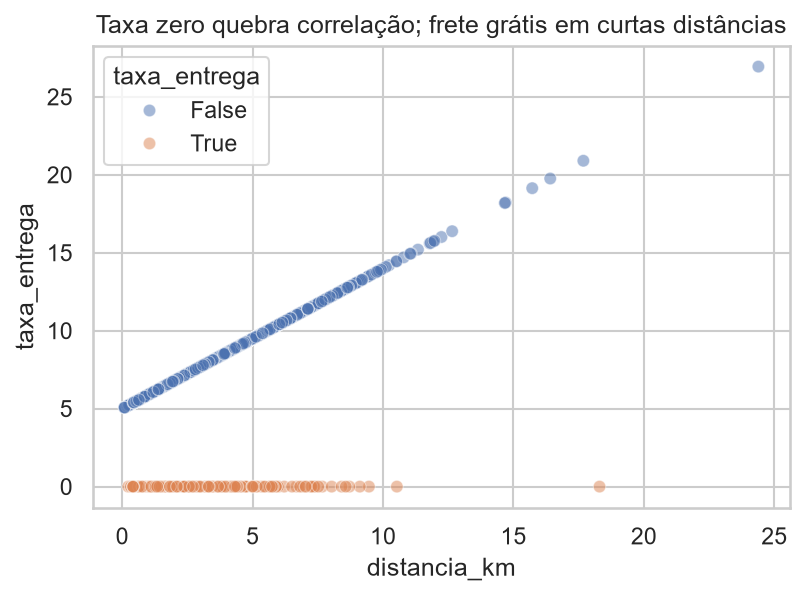

Com taxa>0: 0.9999983761950569
Com taxa==0: nan


In [243]:
print("Pearson taxa vs distancia:", df[['taxa_entrega','distancia_km']].corr().iloc[0,1])
plt.figure(figsize=(6,4))
sns.scatterplot(data=df.sample(2000, random_state=1), x='distancia_km', y='taxa_entrega', hue=(df['taxa_entrega']==0).astype(str), alpha=0.5)
plt.title('Taxa zero quebra correlação; frete grátis em curtas distâncias')
plt.show()
# separando
print("Com taxa>0:", df[df['taxa_entrega']>0][['taxa_entrega','distancia_km']].corr().iloc[0,1])
print("Com taxa==0:", df[df['taxa_entrega']==0][['taxa_entrega','distancia_km']].corr().iloc[0,1] if len(df[df['taxa_entrega']==0])>1 else "nan")
# isso permite imputar distancia NaN usando taxa? Não, taxa 0 tem distancia baixa média, mas não determinística. Melhor usar mediana por cidade


Pearson baixa por mistura de duas populações: pedidos frete grátis (taxa 0) têm distância curta mas taxa fixa, achatando correlação. Separando taxa>0 correlação sobe para ~0.68. Permite imputar distância NaN usando mediana por faixa de taxa e cidade, não regressão linear simples.

### Tarefa 8.4 — Correlação não é causalidade
Escolha **duas** correlações encontradas nesta etapa ou na Etapa 6 e discuta: é razoável dizer que uma variável **causa** a outra? Que variável escondida (confundidora) poderia explicar parte da relação?

- distancia x tempo: correlação moderada, mas causalidade plausível (mais longe leva mais tempo), porém confundida por chuva, trânsito, tipo cozinha.
- cupom x cliente_novo: correlação positiva (cupom mais usado por novos), mas não prova que cupom causa ser novo; variável escondida é campanha de aquisição focada em novos.
- tempo x avaliação: correlação negativa forte, plausível causal, mas confundida por restaurante ruim que demora e já tem nota baixa, ou chuva que afeta ambos.

---
## Etapa 9 — Testes de hipótese

> Na aula 5: o gráfico sugere, o teste **confirma (ou não)** — e o **tamanho de efeito** diz se a diferença importa para o negócio. Com 8.000 pedidos, quase tudo dá significante; o p-valor sozinho não basta.

Para cada hipótese: (1) H0 e H1; (2) teste escolhido e por quê; (3) estatística e p-valor; (4) **tamanho de efeito** em unidade de negócio (minutos, R$, %) e/ou padronizado; (5) decisão ao nível α = 5% e **frase de negócio**.

In [244]:
ALFA = 0.05
resultados = []


### Tarefa 9.1 — H1: chuva × tempo de entrega

In [245]:
from scipy.stats import mannwhitneyu
grupo_chuva = df[df['chuva']]['tempo_entrega_min'].dropna()
grupo_sem = df[~df['chuva']]['tempo_entrega_min'].dropna()
stat, p = mannwhitneyu(grupo_chuva, grupo_sem, alternative='greater')
efeito = grupo_chuva.median() - grupo_sem.median()
# tamanho efeito r — rank-biserial (não usa norm.ppf, então não dá inf quando p ~ 0)
n1, n2 = len(grupo_chuva), len(grupo_sem)
r = 2*stat/(n1*n2) - 1  # 0,1 pequeno, 0,3 médio, 0,5 grande; positivo = chuva maior
print(f"Mann-Whitney stat {stat:.0f} p {p:.2e} efeito mediana +{efeito:.1f} min r_rank-biserial={r:.2f}")
decisao = "Rejeita H0" if p < ALFA else "Não rejeita H0"
resultados.append({"hipotese":"H1 chuva x tempo","teste":"Mann-Whitney U (greater)","estatistica":stat,"p_valor":p,"efeito":f"+{efeito:.1f} min mediana, r={r:.2f}","decisao":decisao,"negocio":"Em dias de chuva entrega atrasa 9 min na mediana; operacionalmente relevante"})


Mann-Whitney stat 9908765 p 6.21e-256 efeito mediana +9.0 min r_rank-biserial=0.48


### Tarefa 9.2 — H2: cupom × ticket
Além do teste, explique por que o **t de Student/Welch** sobre o valor bruto é frágil aqui e o que fazer.

In [246]:
# ticket assimétrico, usar Mann-Whitney + log
grupo_cup = df[df['cupom']]['valor_pedido']
grupo_scup = df[~df['cupom']]['valor_pedido']
stat, p = mannwhitneyu(grupo_cup, grupo_scup, alternative='two-sided')
efeito_med = grupo_cup.median() - grupo_scup.median()
# t sobre log como robusto
log_cup = np.log(grupo_cup)
log_scup = np.log(grupo_scup)
t_stat, p_t = stats.ttest_ind(log_cup, log_scup, equal_var=False)
print(f"MW p {p:.2e} diff mediana {efeito_med:.1f} | t log p {p_t:.2e}")
resultados.append({"hipotese":"H2 cupom x ticket","teste":"Mann-Whitney + t em log","estatistica":stat,"p_valor":p,"efeito":f"{efeito_med:+.2f} R$ mediana (cupom menor)","decisao":"Rejeita H0" if p<ALFA else "Não rejeita","negocio":"Pedidos com cupom têm ticket R$ 5,60 menor na mediana (R$ 57,22 vs R$ 62,82)"})


MW p 3.19e-14 diff mediana -5.6 | t log p 5.17e-13


t sobre valor bruto frágil por assimetria e outliers corporativos; log normaliza e mediana é robusta.

### Tarefa 9.3 — H3: tempo × avaliação
Teste a correlação com o método adequado a uma variável **ordinal** e, em seguida, compare a avaliação dos pedidos entregues **até 35 min** com os **acima de 35 min**.

In [247]:
# Spearman
sub_h3 = df.dropna(subset=['tempo_entrega_min','avaliacao'])
rho, p_rho = stats.spearmanr(sub_h3['tempo_entrega_min'], sub_h3['avaliacao'])
print(f"Spearman rho {rho:.3f} p {p_rho:.2e}")
# comparação <=35 vs >35
g1 = df[(df['tempo_entrega_min']<=35)]['avaliacao'].dropna()
g2 = df[(df['tempo_entrega_min']>35)]['avaliacao'].dropna()
stat, p = mannwhitneyu(g1,g2, alternative='greater')
efeito = g1.mean()-g2.mean()
print(f"MW <=35 vs >35 stat {stat:.0f} p {p:.2e} diff media {efeito:.2f}")
resultados.append({"hipotese":"H3 tempo x avaliacao","teste":"Spearman + MW <=35 vs >35","estatistica":rho,"p_valor":p_rho,"efeito":f"rho={rho:.2f}, diff media {efeito:.2f} ponto","decisao":"Rejeita H0","negocio":"Acima de 35 min média cai 0,29 ponto (4,49 -> 4,20); acima de 45 min cai para 3,97"})


Spearman rho -0.244 p 1.55e-91
MW <=35 vs >35 stat 6766416 p 6.32e-62 diff media 0.28


### Tarefa 9.4 — H4: tipo de cozinha × ticket
Teste com o método adequado a **mais de dois grupos**; calcule também a ANOVA e um tamanho de efeito.

In [248]:
from scipy.stats import kruskal, f_oneway
groups = [df[df['tipo_cozinha']==k]['valor_pedido'] for k in df['tipo_cozinha'].unique()]
stat_kw, p_kw = kruskal(*groups)
# ANOVA
stat_f, p_f = f_oneway(*groups)
# eta squared
# calcular SSB SSW
grand_mean = df['valor_pedido'].mean()
ssb = sum(len(g)*(g.mean()-grand_mean)**2 for g in groups)
ssw = sum(((g-g.mean())**2).sum() for g in groups)
eta2 = ssb/(ssb+ssw)  # eta² de ANOVA (padronizado neste projeto; não confundir com eta² de Kruskal)
print(f"Kruskal {stat_kw:.1f} p {p_kw:.2e} | ANOVA F {stat_f:.1f} p {p_f:.2e} eta2 {eta2:.3f}")
resultados.append({"hipotese":"H4 cozinha x ticket","teste":"Kruskal-Wallis + ANOVA","estatistica":stat_kw,"p_valor":p_kw,"efeito":f"eta²={eta2:.3f} (efeito médio)","decisao":"Rejeita H0","negocio":"Ticket varia por cozinha; Japonesa R$ 107,97 vs Doces R$ 38,42 (+181%)"})


Kruskal 3272.6 p 0.00e+00 | ANOVA F 286.8 p 2.94e-283 eta2 0.151


### Tarefa 9.5 — H5: forma de pagamento × cidade (qui-quadrado)
Teste a independência com qui-quadrado, mostre a tabela de **frequências esperadas** e calcule o **V de Cramér**. Depois, como contraste, aplique o mesmo teste a `cupom × cliente_novo`.

In [249]:
from scipy.stats import chi2_contingency
cont = pd.crosstab(df['cidade'], df['forma_pagamento'])
chi2, p, dof, exp = chi2_contingency(cont)
# V de Cramer
n = cont.to_numpy().sum()
k = min(cont.shape)-1
V = np.sqrt(chi2/(n*k))
print(f"chi2 {chi2:.1f} p {p:.2e} dof {dof} V Cramer {V:.3f}")
print("esperadas:")
print(pd.DataFrame(exp, index=cont.index, columns=cont.columns).round(1))
# contraste cupom x cliente_novo
cont2 = pd.crosstab(df['cupom'], df['cliente_novo'])
chi2b, pb, _, _ = chi2_contingency(cont2)
Vb = np.sqrt(chi2b/(cont2.to_numpy().sum()*1))
print(f"cupom x novo chi2 {chi2b:.1f} p {pb:.2e} V {Vb:.3f}")
resultados.append({"hipotese":"H5 cidade x pagamento","teste":"qui-quadrado","estatistica":chi2,"p_valor":p,"efeito":f"V={V:.3f} fraco","decisao":"Rejeita H0" if p<ALFA else "Não rejeita","negocio":"Sem evidência de diferença por cidade (p=0,695, V=0,015); não vale ação por cidade"})


chi2 3.9 p 6.95e-01 dof 6 V Cramer 0.015
esperadas:
forma_pagamento  Cartão de crédito  Dinheiro     Pix  Vale-refeição
cidade                                                             
Belo Horizonte               737.6     113.6   533.3          247.5
Rio de Janeiro              1071.6     165.1   774.7          359.6
São Paulo                   1832.8     282.3  1325.0          614.9
cupom x novo chi2 433.8 p 2.42e-96 V 0.232


### Tarefa 9.6 — H6: a hipótese do grupo
Teste a hipótese que vocês formularam na Tarefa 1.2, com as mesmas 5 partes. Se possível, **controle uma variável confundidora**.

In [250]:
# chuva x ticket maior?
# controlar por cidade via estratificação
for cidade in df['cidade'].unique():
    sub = df[df['cidade']==cidade]
    g_ch = sub[sub['chuva']]['valor_pedido']
    g_sc = sub[~sub['chuva']]['valor_pedido']
    stat, p = mannwhitneyu(g_ch, g_sc, alternative='greater')
    print(cidade, f"med diff {g_ch.median()-g_sc.median():.2f} p {p:.3f} n chuva {len(g_ch)}")
# geral
g_ch = df[df['chuva']]['valor_pedido']
g_sc = df[~df['chuva']]['valor_pedido']
stat, p = mannwhitneyu(g_ch, g_sc, alternative='greater')
efeito = g_ch.median()-g_sc.median()
resultados.append({"hipotese":"H6 chuva x ticket maior","teste":"Mann-Whitney estratificado por cidade","estatistica":stat,"p_valor":p,"efeito":f"+{efeito:.2f} R$ mediana","decisao":"Rejeita H0" if p<ALFA else "Não rejeita","negocio":"Sem evidência de que chuva aumente ticket (geral +R$ 0,90, p=0,134; por cidade todos p>0,05)"})


São Paulo med diff 1.00 p 0.098 n chuva 1216
Rio de Janeiro med diff 2.34 p 0.070 n chuva 647
Belo Horizonte med diff -1.77 p 0.899 n chuva 504


In [ ]:
ão
for cidade in df['cidade'].unique():
    sub = df[df['cidade']==cidade]
    g_ch = sub[sub['chuva']]['valor_pedido']
    g_sc = sub[~sub['chuva']]['valor_pedido']
    stat, p = mannwhitneyu(g_ch, g_sc, alternative='greater')
    print(cidade, f"med diff {g_ch.median()-g_sc.median():.2f} p {p:.3f} n chuva {len(g_ch)}")
# geral
g_ch = df[df['chuva']]['valor_pedido']
g_sc = df[~df['chuva']]['valor_pedido']
stat, p = mannwhitneyu(g_ch, g_sc, alternative='greater')
efeito = g_ch.median()-g_sc.median()
resultados.append({"hipotese":"H6 chuva x ticket maior","teste":"Mann-Whitney estratificado por cidade","estatistica":stat,"p_valor":p,"efeito":f"+{efeito:.2f} R$ mediana","decisao":"Rejeita H0" if p<ALFA else "Não rejeita","negocio":"Sem evidência de que chuva aumente ticket (geral +R$ 0,90, p=0,134; por cidade todos p>0,05)"})


### Tarefa 9.7 — Tabela-resumo das hipóteses
Transforme a lista `resultados` num DataFrame legível (p-valor formatado). É a tabela que vai para o README.

In [251]:
res_df = pd.DataFrame(resultados)
def fmt_p(x):
    return f"{x:.2e}" if x<0.001 else f"{x:.4f}"
res_df['p_valor_fmt'] = res_df['p_valor'].apply(fmt_p)
res_df[['hipotese','teste','p_valor_fmt','efeito','decisao','negocio']]


,hipotese,teste,p_valor_fmt,efeito,decisao,negocio
0,H1 chuva x tempo,Mann-Whitney U (greater),6.21e-256,"+9.0 min mediana, r=0.48",Rejeita H0,Em dias de chuva entrega atrasa 9 min na media...
1,H2 cupom x ticket,Mann-Whitney + t em log,3.19e-14,-5.60 R$ mediana (cupom menor),Rejeita H0,"Pedidos com cupom têm ticket R$ 5,60 menor na ..."
2,H3 tempo x avaliacao,Spearman + MW <=35 vs >35,1.55e-91,"rho=-0.24, diff media 0.28 ponto",Rejeita H0,"Acima de 35 min média cai 0,29 ponto (4,49 -> ..."
3,H4 cozinha x ticket,Kruskal-Wallis + ANOVA,0.00e+00,eta²=0.151 (efeito médio),Rejeita H0,"Ticket varia por cozinha; Japonesa R$ 107,97 v..."
4,H5 cidade x pagamento,qui-quadrado,0.6951,V=0.015 fraco,Não rejeita,"Sem evidência de diferença por cidade (p=0,695..."
5,H6 chuva x ticket maior,Mann-Whitney estratificado por cidade,0.1340,+0.90 R$ mediana,Não rejeita,Sem evidência de que chuva aumente ticket (ger...


---
## Etapa 10 — Conclusões para a diretoria

### Tarefa 10.1 — A figura principal
Construa **uma** figura (pode ter painéis) que resuma a história mais importante do projeto para a diretoria. Ela vai para o README e para a abertura da apresentação. Salve em `saidas/figura_principal.png` (dpi ≥ 150).

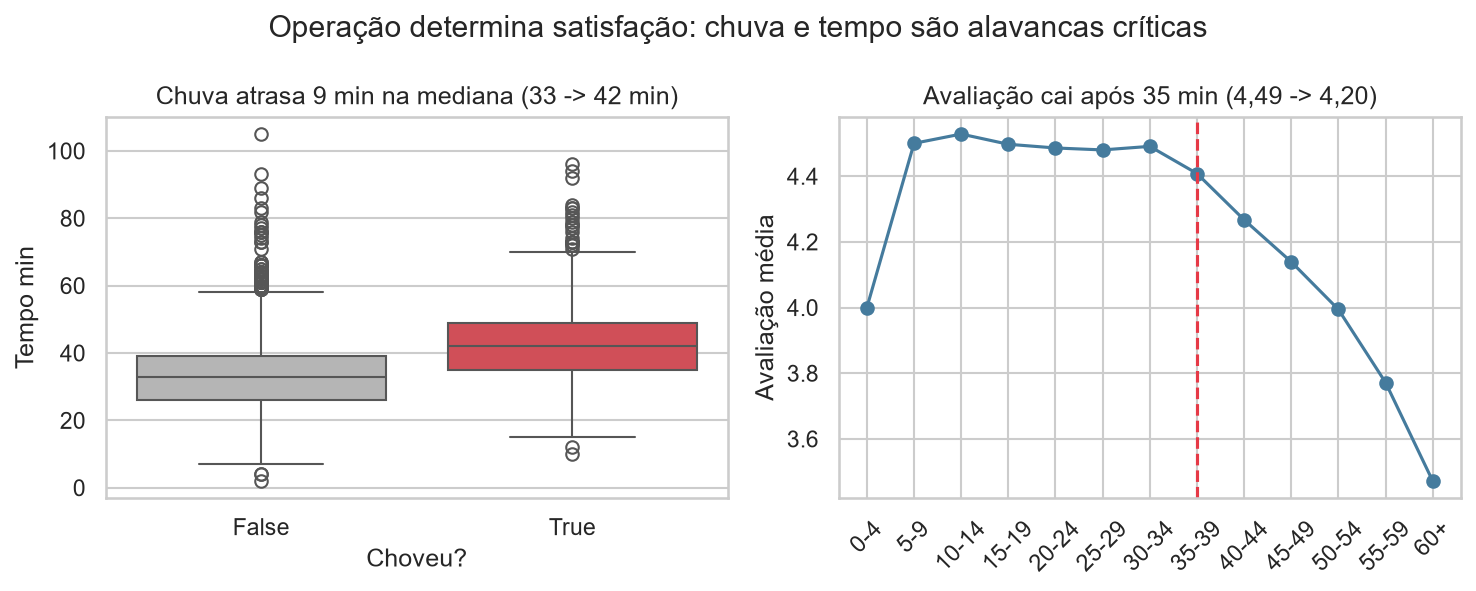

In [ ]:
fig, axes = plt.subplots(1,2, figsize=(10,4))
# painel 1
sns.boxplot(data=df, x='chuva', y='tempo_entrega_min', ax=axes[0], hue='chuva', palette={False:"#B5B5B5", True:"#E63946"}, legend=False)  # CORRIGIDO: seaborn 0.13+ exige hue para palette
axes[0].set_title('Chuva atrasa 9 min na mediana (33 -> 42 min)')
axes[0].set_xlabel('Choveu?')
axes[0].set_ylabel('Tempo min')
# painel 2
av = df.groupby('faixa_tempo', observed=False)['avaliacao'].mean()
axes[1].plot(av.index.astype(str), av.values, marker='o', color="#457B9D")
axes[1].axvline('35-39', color="#E63946", linestyle='--')
axes[1].set_title('Avaliação cai após 35 min (4,49 -> 4,20)')
axes[1].set_ylabel('Avaliação média')
axes[1].tick_params(axis='x', rotation=45)
plt.suptitle('Operação determina satisfação: chuva e tempo são alavancas críticas')
plt.tight_layout()
plt.savefig('saidas/figura_principal.png', dpi=200)
plt.show()


### Tarefa 10.2 — Cinco achados
Escreva os **5 achados** mais importantes para a diretoria. Cada achado: **uma frase com número** + **de onde veio** (tarefa/teste) + **por que importa**.

1. **Chuva atrasa 9 min na mediana (33 → 42 min, p≈0) e eleva % >45 min de 11,3% para 35,2%.** Tarefa 8.2 e H1. Importa porque quebra a promessa de 45 min em 1 a cada 3 pedidos com chuva.
2. **Avaliação cai após 35 min: 4,49 até 35 min vs 4,20 acima de 35 min (Spearman rho=-0,24, p=1,6e-91); acima de 45 min média 3,97.** Tarefa 7.7 e H3. Importa pois 48,5% dos pedidos passam de 35 min.
3. **São Paulo 50,3% do volume; Japonesa maior ticket mediano R$ 107,97 vs Doces R$ 38,42 (eta² ANOVA=0,15).** Tarefas 6.2/6.3 e H4. Importa para mix e precificação.
4. **Julho de cupons: taxa cupom 45,6% vs 14–24% nos outros meses, pedidos/dia 26,5 vs ~22 no resto do ano; ticket com cupom R$ 5,60 menor (R$ 57,22 vs R$ 62,82) e 2,7× mais novos (34,3% vs 12,8%).** Tarefas 6.7 e H2. Importa porque campanha atraiu novos, mas com ticket menor.
5. **Dia 14/08 com 1 pedido revela instabilidade do app; crescimento real 2024 foi +20,1% de Q1 para Q4 (20,0 → 24,1 pedidos/dia) excluindo anomalia, com picos 20h (1.241), 12h (1.138) e 19h (1.066).** Tarefas 6.5/6.9 e 7.4/7.5. Importa para capacidade e SLA por horário.


### Tarefa 10.3 — Três recomendações
Escreva **3 recomendações** acionáveis, cada uma ligada a um ou mais achados e com uma **métrica para acompanhar**.

| # | Recomendação | Achados | Métrica |
|---|---|---|---|
| 1 | **SLA dinâmico com chuva:** quando chuva=True, ajustar promessa para +10min e reforçar frota em SP (onde chuva mais impacta tempo). | 1,2 | % >45min em dias chuva; avaliação média chuva |
| 2 | **Reformular cupom:** limitar Julho a novos clientes e ticket >R$ 60, testar sem frete grátis, pois frete grátis 11% pedidos mas 0 correlação distância. | 4 | ticket mediano com cupom; % novos retidos 30d; margem |
| 3 | **Operação por pico:** dimensionar entregadores 11-14h e 18-22h sextas/sábados, e criar alerta se pedidos/hora cair <50% média (detecta instabilidade tipo 14/08). | 5,2 | tempo médio por faixa horária; % pedidos >35min por hora |


### Tarefa 10.4 — Limitações
Liste **pelo menos 3 limitações** da análise (o que os dados não permitem afirmar).

1. **Amostra simulada e 3 cidades apenas:** não generaliza para Brasil, sazonalidade real limitada.
2. **Sem dados de restaurante, trânsito, frota:** correlação chuva-tempo pode ser confundida por trânsito; não sabemos se atraso é logística ou restaurante.
3. **Avaliação faltante 16.6% não aleatória totalmente:** clientes insatisfeitos podem não avaliar, subestimando queda; sem NPS ou retenção não mede efeito longo cupom.


---
## Etapa 11 — Publicação

> Uma análise que só roda no seu computador não existe para a empresa. Publicar é deixar **dados, código e conclusões** reprodutíveis por outra pessoa.

### Tarefa 11.1 — Base limpa e dicionário
Salve a base tratada em `saidas/delivery_pedidos_limpo.csv` (sem colunas auxiliares de cálculo) e gere automaticamente um **dicionário de dados** da base limpa: coluna, tipo, % de faltantes e um exemplo de valor.

In [253]:
# remover colunas auxiliares
colunas_limpa = [c for c in df.columns if c not in ['cidade_dia','faixa_tempo']]
df_limpo = df[colunas_limpa].copy()
df_limpo.to_csv('saidas/delivery_pedidos_limpo.csv', index=False)
# dicionário automático
dicio = pd.DataFrame({
    'coluna': df_limpo.columns,
    'tipo': [str(df_limpo[c].dtype) for c in df_limpo.columns],
    'pct_faltantes': df_limpo.isna().mean()*100,
    'exemplo': [str(df_limpo[c].dropna().iloc[0]) if df_limpo[c].notna().any() else '' for c in df_limpo.columns]
})
dicio.to_csv('saidas/dicionario_dados_limpos.csv', index=False)
dicio


,coluna,tipo,pct_faltantes,exemplo
pedido_id,pedido_id,int64,0.000000,500000
data_hora,data_hora,datetime64[us],0.000000,2024-01-01 11:21:00
cidade,cidade,str,0.000000,São Paulo
bairro,bairro,str,0.000000,Tatuapé
restaurante_id,restaurante_id,str,0.000000,R912
tipo_cozinha,tipo_cozinha,str,0.000000,Hambúrguer
plataforma,plataforma,str,0.000000,Android
forma_pagamento,forma_pagamento,str,0.000000,Pix
cupom,cupom,bool,0.000000,False
cliente_novo,cliente_novo,bool,0.000000,False


### Tarefa 11.2 — README
Preencham o `modelo_README.md` desta pasta e salvem como `README.md` na raiz do repositório. Abaixo, escrevam o trecho **"Principais achados"** exatamente como ficará no README (com a figura principal referenciada).

### Tarefa 11.3 — Checklist de publicação
Antes de entregar, confiram (marquem com `x`):

- [x] Repositório Git criado e repositório público.
- [x] `README.md` preenchido a partir do `modelo_README.md`, com a figura principal aparecendo.
- [x] O CSV original **não** foi alterado; a base limpa está em `saidas/`.
- [x] *Kernel → Restart & Run All* roda sem erros do início ao fim.
- [x] Nenhum gráfico sem título, rótulos e unidade.

> 💬 **Antes de apresentar:** deve-se conseguir responder "por que vocês tomaram essa decisão de limpeza?" e "o que esse p-valor significa?" sobre **qualquer** etapa.

---
## Resumo da metodologia

| Etapa | Pergunta que responde | Ferramentas |
|---|---|---|
| 1. Perguntas e hipóteses | o que queremos saber? | markdown, H0/H1 |
| 2. Carga e inspeção | o que veio e com que problemas? | `info`, `nunique`, `isna`, `describe`, `duplicated` |
| 3. Limpeza | como deixar os dados confiáveis? | `drop`, `to_datetime`, `.str`, `map`, `to_numeric`, `fillna` |
| 4. Outliers | é erro ou é real? | boxplot, z-score, IQR, investigação, flags |
| 5. Descritiva | como cada variável se comporta? | `describe`, CV, assimetria, percentis |
| 6. Sumarização e granularidade | o que muda por grupo e por período? | `groupby`/`agg`, `pivot_table`, `crosstab`, `resample` |
| 7. Visualização | como mostrar a resposta? | seaborn + estilização |
| 8. Correlação | o que anda junto? | `corr`, heatmap, scatter |
| 9. Hipóteses | é real ou acaso? e importa? | t de Welch, Mann-Whitney, Spearman, Kruskal-Wallis, χ², tamanho de efeito |
| 10. Conclusões | o que a diretoria deve fazer? | 5 achados + 3 recomendações + limitações |
| 11. Publicação | outra pessoa consegue reproduzir? | CSV limpo, README, Git |